<a href="https://colab.research.google.com/github/fitridianamusa/Artikel-ADW-Kelompok-8/blob/main/GARCH_LSTM_Hybrid_OneStep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forecasting Kurs USD/IDR dengan Log Return
## AR(1)-GARCH(1,1), LSTM, dan Hybrid GARCH-LSTM — Rolling One-Step-Ahead

Notebook ini menggunakan **log return** sebagai target model. Pada setiap tanggal testing, model memprediksi satu periode ke depan dengan hanya menggunakan informasi yang tersedia sebelum tanggal tersebut.

**Catatan interpretasi:** log return finansial sering berfluktuasi di sekitar nol. Karena itu, prediksi return yang relatif datar tidak otomatis berarti kode salah. Grafik harga one-step-ahead direkonstruksi menggunakan **harga aktual periode sebelumnya**, bukan akumulasi seluruh return prediksi.

## 1. Instalasi dan import library
Jalankan instalasi jika paket belum tersedia.

In [2]:
# Jika perlu, jalankan sekali:
%pip install arch tensorflow statsmodels scikit-learn seaborn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from arch import arch_model
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(123)
tf.keras.utils.set_random_seed(123)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 14.0 MB/s  0:00:00
Pandas: 2.2.3
TensorFlow: 2.21.0


## 2. Membaca dan membersihkan data
Sumber data CSV yang digunakan sama dengan notebook sebelumnya. Kode mencoba mengenali kolom tanggal dan kurs.

In [3]:
url = (
    "https://raw.githubusercontent.com/"
    "fitridianamusa/Artikel-ADW-Kelompok-8/"
    "main/Data%20Historis%20USD_IDR.csv"
)
df = pd.read_csv(url, encoding="utf-8-sig")
df.columns = df.columns.astype(str).str.strip()

print("Kolom sumber:", df.columns.tolist())
display(df.head())

Kolom sumber: ['Tanggal', 'Terakhir', 'Pembukaan', 'Tertinggi', 'Terendah', 'Vol.', 'Perubahan%']


,Tanggal,Terakhir,Pembukaan,Tertinggi,Terendah,Vol.,Perubahan%
0,01/09/2026,"17.715,0","17.725,0","17.735,0","17.704,5",NaN,"0,00%"
1,31/08/2026,"17.715,0","17.750,0","17.770,0","17.712,5",NaN,"0,14%"
2,28/08/2026,"17.690,0","17.715,0","17.722,5","17.679,0",NaN,"-0,17%"
3,27/08/2026,"17.720,0","17.760,0","17.790,0","17.720,0",NaN,"0,11%"
4,26/08/2026,"17.700,0","17.695,0","17.733,5","17.677,5",NaN,"-0,06%"


In [4]:
kolom_tanggal = next(
    (c for c in df.columns if c.lower().strip() in ["tanggal", "date", "datetime"]),
    None
)
kolom_kurs = next(
    (c for c in df.columns if c.lower().strip() in ["terakhir", "last", "close", "closing price", "kurs"]),
    None
)

if kolom_tanggal is None:
    raise ValueError("Kolom tanggal tidak ditemukan. Periksa nama kolom CSV.")
if kolom_kurs is None:
    raise ValueError("Kolom harga/kurs tidak ditemukan. Periksa nama kolom CSV.")

data = df[[kolom_tanggal, kolom_kurs]].copy()
data.columns = ["Tanggal", "Kurs"]

data["Tanggal"] = pd.to_datetime(data["Tanggal"], dayfirst=True, errors="coerce")

def konversi_angka(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.number)):
        return float(x)
    x = str(x).strip().replace(" ", "")
    if "," in x and "." in x:
        if x.rfind(",") > x.rfind("."):
            x = x.replace(".", "").replace(",", ".")
        else:
            x = x.replace(",", "")
    elif "," in x:
        x = x.replace(",", ".")
    x = x.replace("%", "")
    try:
        return float(x)
    except ValueError:
        return np.nan

data["Kurs"] = data["Kurs"].apply(konversi_angka)
data = data.dropna(subset=["Tanggal", "Kurs"])
data = data[data["Kurs"] > 0]
data = data.drop_duplicates(subset="Tanggal", keep="first")
data = data.sort_values("Tanggal").reset_index(drop=True)

print("Jumlah observasi:", len(data))
print("Periode:", data["Tanggal"].min(), "sampai", data["Tanggal"].max())
display(data.head())

Jumlah observasi: 1442
Periode: 2021-01-01 00:00:00 sampai 2026-09-01 00:00:00


,Tanggal,Kurs
0,2021-01-01,14213.7
1,2021-01-04,13885.0
2,2021-01-05,13900.0
3,2021-01-06,13880.0
4,2021-01-07,13890.0


## 3. Menghitung log return dan membagi data
Log return dihitung sebagai ln(Kurs_t) − ln(Kurs_{t−1}). Data dibagi secara kronologis, bukan acak.

Total observasi log return: 1441
Training: 1152 | Testing: 289
Periode training: 2021-01-04 00:00:00 sampai 2025-07-23 00:00:00
Periode testing : 2025-07-24 00:00:00 sampai 2026-09-01 00:00:00


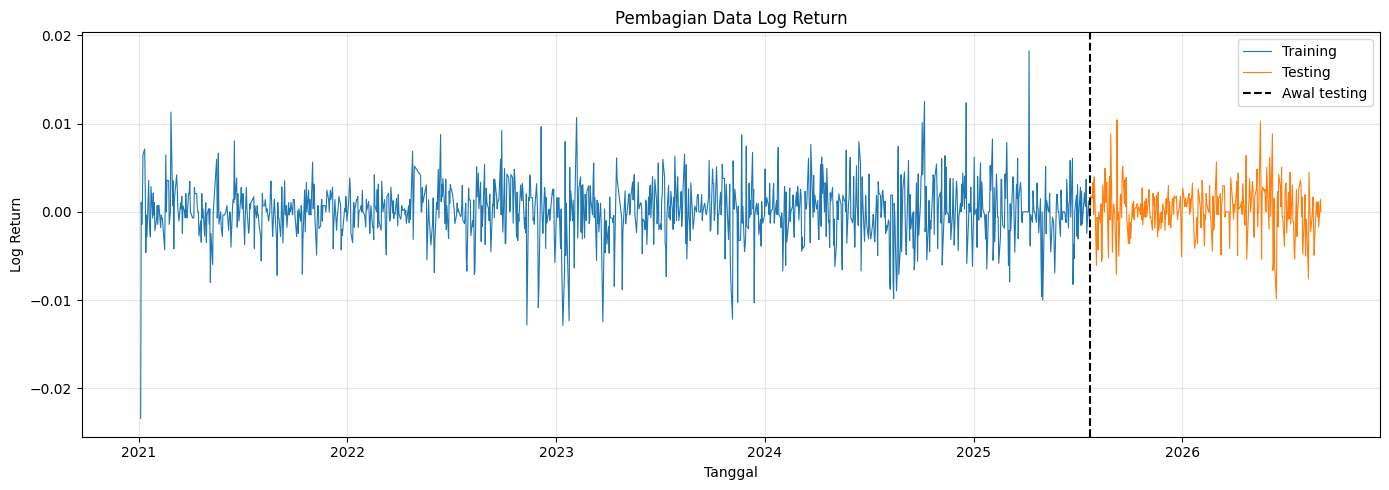

In [5]:
data["Log_Return"] = np.log(data["Kurs"]).diff()
data_return = data.dropna(subset=["Log_Return"]).reset_index(drop=True).copy()

proporsi_train = 0.80
n = len(data_return)
batas = int(n * proporsi_train)

train = data_return.iloc[:batas].copy()
test = data_return.iloc[batas:].copy()

r_train = train["Log_Return"].astype(float)
r_test = test["Log_Return"].astype(float)

print("Total observasi log return:", n)
print("Training:", len(train), "| Testing:", len(test))
print("Periode training:", train["Tanggal"].min(), "sampai", train["Tanggal"].max())
print("Periode testing :", test["Tanggal"].min(), "sampai", test["Tanggal"].max())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train["Tanggal"], r_train, label="Training", linewidth=0.8)
ax.plot(test["Tanggal"], r_test, label="Testing", linewidth=0.8)
ax.axvline(test["Tanggal"].iloc[0], color="black", linestyle="--", label="Awal testing")
ax.set(title="Pembagian Data Log Return", xlabel="Tanggal", ylabel="Log Return")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Diagnostik awal
Pengujian ini membantu memahami sifat log return dan indikasi efek ARCH.

ADF statistic: -11.703191
ADF p-value  : 1.55098e-21
Kesimpulan ADF: stasioner menurut uji ADF (5%)


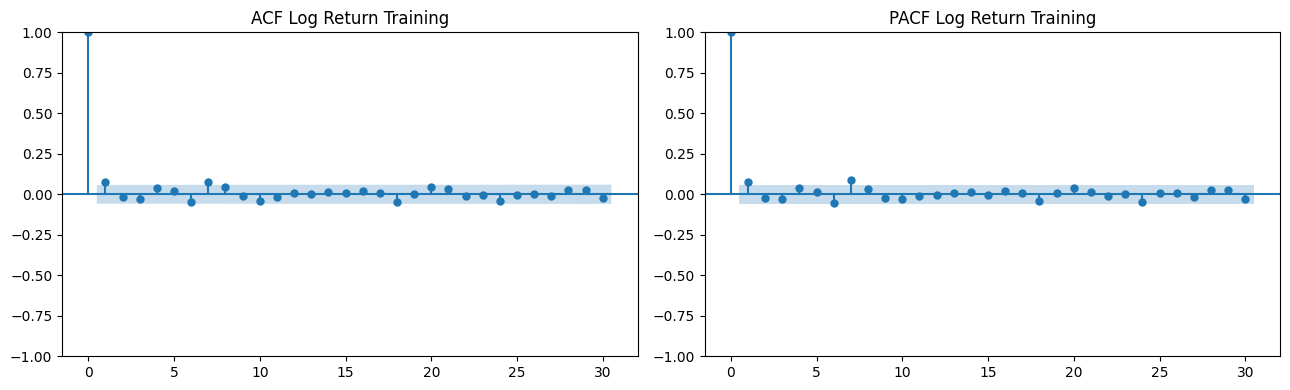

Ljung-Box return:


,lb_stat,lb_pvalue
5,10.541504,0.061268
10,24.667386,0.006013
20,30.411648,0.063452


ARCH-LM statistic: 28.300598
ARCH-LM p-value  : 0.00161558


In [6]:
adf = adfuller(r_train.dropna(), autolag="AIC")
print(f"ADF statistic: {adf[0]:.6f}")
print(f"ADF p-value  : {adf[1]:.6g}")
print("Kesimpulan ADF:", "stasioner menurut uji ADF (5%)" if adf[1] < 0.05 else "belum cukup bukti stasioner menurut uji ADF (5%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(r_train, lags=min(30, len(r_train)//2-1), ax=axes[0])
axes[0].set_title("ACF Log Return Training")
plot_pacf(r_train, lags=min(30, len(r_train)//2-1), method="ywm", ax=axes[1])
axes[1].set_title("PACF Log Return Training")
plt.tight_layout()
plt.show()

print("Ljung-Box return:")
display(acorr_ljungbox(r_train, lags=[5, 10, 20], return_df=True))

arch_test = het_arch(r_train, nlags=10)
print(f"ARCH-LM statistic: {arch_test[0]:.6f}")
print(f"ARCH-LM p-value  : {arch_test[1]:.6g}")

## 5. Estimasi AR(1)-GARCH(1,1) pada training
Return dikalikan 100 untuk membantu kestabilan numerik. Semua prediksi nanti dikembalikan ke skala log return dengan membagi 100.

In [7]:
r_train_pct = 100.0 * r_train

model_ar1_garch = arch_model(
    r_train_pct,
    mean="AR",
    lags=1,
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=False
)
hasil_ar1_garch = model_ar1_garch.fit(disp="off", show_warning=False)

print(hasil_ar1_garch.summary())
print("\nParameter model:")
display(hasil_ar1_garch.params)

                           AR - GARCH Model Results                           
Dep. Variable:             Log_Return   R-squared:                       0.006
Mean Model:                        AR   Adj. R-squared:                  0.005
Vol Model:                      GARCH   Log-Likelihood:               -285.703
Distribution:                  Normal   AIC:                           581.406
Method:            Maximum Likelihood   BIC:                           606.648
                                        No. Observations:                 1151
Date:                Tue, Oct 27 2026   Df Residuals:                     1149
Time:                        09:44:15   Df Model:                            2
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
--------------------------------------------------------------------------------
Const             0.0133  8.880e-03      1.501

,params
Const,0.013332
Log_Return[1],0.080778
omega,0.000548
alpha[1],0.022990
beta[1],0.971969


## 6. Melatih LSTM untuk log return
Scaler hanya di-fit pada training. Model dilatih untuk memprediksi return berikutnya berdasarkan `LOOKBACK` return aktual sebelumnya.

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0663 - val_loss: 0.0110
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0092 - val_loss: 0.0080
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0092 - val_loss: 0.0080
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0084 - val_loss: 0.0079
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0077 - val_loss: 0.0080
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0079 - val_loss: 0.0079
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0083 - val_loss: 0.0079
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0081 - val_loss: 0.0079
Epoch 9/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0079 - val_loss: 0.0079
Epoch 10/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0079 - val_loss: 0.0079
Epoch 11/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0074 - val_loss: 0.0079
Epoch 12/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss

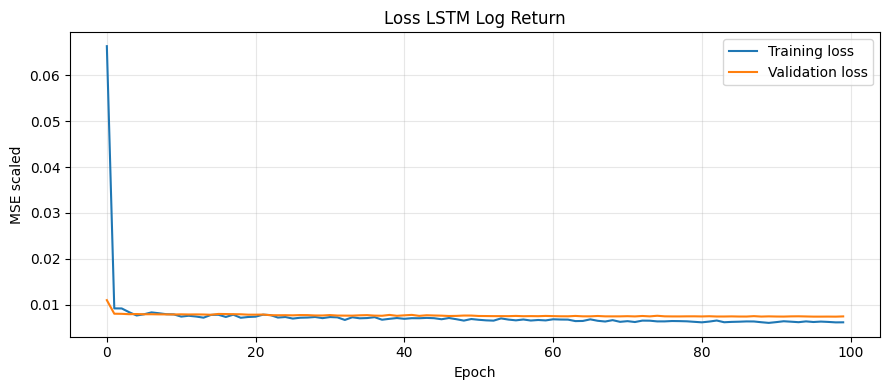

In [8]:
LOOKBACK = 10
N_UNIT_LSTM = 50
DROPOUT_RATE = 0.2
EPOCHS = 100
BATCH_SIZE = 32

train_pct = (100.0 * r_train.to_numpy()).reshape(-1, 1)

scaler_return = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler_return.fit_transform(train_pct)

def buat_sequences(data_scaled, lookback):
    X, y = [], []
    for j in range(lookback, len(data_scaled)):
        X.append(data_scaled[j-lookback:j, 0])
        y.append(data_scaled[j, 0])
    return np.asarray(X).reshape(-1, lookback, 1), np.asarray(y)

X_train_lstm, y_train_lstm = buat_sequences(train_scaled, LOOKBACK)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(123)

model_lstm = Sequential([
    Input(shape=(LOOKBACK, 1)),
    LSTM(N_UNIT_LSTM),
    Dropout(DROPOUT_RATE),
    Dense(1)
])
model_lstm.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

plt.figure(figsize=(9, 4))
plt.plot(history_lstm.history["loss"], label="Training loss")
plt.plot(history_lstm.history["val_loss"], label="Validation loss")
plt.title("Loss LSTM Log Return")
plt.xlabel("Epoch")
plt.ylabel("MSE scaled")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Melatih LSTM untuk koreksi residual GARCH (komponen hybrid)
LSTM kedua dilatih pada residual in-sample model AR(1)-GARCH yang diestimasi pada training. Saat testing, koreksi diprediksi dari residual yang tersedia sampai periode sebelumnya.

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0482 - val_loss: 0.0149
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0129 - val_loss: 0.0140
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0130 - val_loss: 0.0140
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0124 - val_loss: 0.0139
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0119 - val_loss: 0.0139
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0120 - val_loss: 0.0139
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0116 - val_loss: 0.0138
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0114 - val_loss: 0.0138
Epoch 9/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0115 - val_loss: 0.0138
Epoch 10/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0112 - val_loss: 0.0137
Epoch 11/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0111 - val_loss: 0.0137
Epoch 12/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - lo

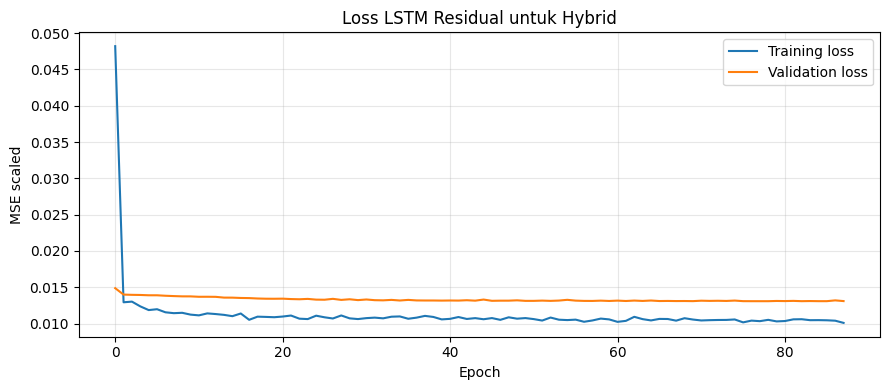

Jumlah residual training: 1151


In [9]:
# Residual training dari AR(1)-GARCH; skalanya adalah persen log return
residual_train_pct = pd.Series(
    np.asarray(hasil_ar1_garch.resid, dtype=float)
).dropna().to_numpy().reshape(-1, 1)

LOOKBACK_RESID = LOOKBACK
scaler_resid = MinMaxScaler(feature_range=(0, 1))
resid_scaled = scaler_resid.fit_transform(residual_train_pct)

X_train_resid, y_train_resid = buat_sequences(resid_scaled, LOOKBACK_RESID)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(456)

model_resid_lstm = Sequential([
    Input(shape=(LOOKBACK_RESID, 1)),
    LSTM(N_UNIT_LSTM),
    Dropout(DROPOUT_RATE),
    Dense(1)
])
model_resid_lstm.compile(optimizer="adam", loss="mse")

early_stop_resid = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_resid = model_resid_lstm.fit(
    X_train_resid,
    y_train_resid,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_resid],
    verbose=1
)

plt.figure(figsize=(9, 4))
plt.plot(history_resid.history["loss"], label="Training loss")
plt.plot(history_resid.history["val_loss"], label="Validation loss")
plt.title("Loss LSTM Residual untuk Hybrid")
plt.xlabel("Epoch")
plt.ylabel("MSE scaled")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Jumlah residual training:", len(residual_train_pct))

## 8. Rolling one-step-ahead untuk ketiga model

Untuk setiap periode testing:
1. AR(1)-GARCH diestimasi menggunakan training dan return aktual testing yang telah tersedia sebelum target.
2. LSTM memakai `LOOKBACK` return aktual terbaru yang sudah tersedia.
3. LSTM residual memprediksi koreksi dari residual historis yang tersedia.
4. Hybrid = prediksi mean GARCH + prediksi koreksi residual LSTM.
5. Setelah prediksi periode tersebut dibuat, return aktual periode itu baru dimasukkan ke riwayat untuk prediksi langkah berikutnya.

Ini adalah **rolling one-step-ahead**, bukan multi-step rekursif. Proses estimasi ulang GARCH pada setiap titik dapat memerlukan waktu.

In [10]:
r_train_pct_np = 100.0 * r_train.to_numpy(dtype=float)
r_test_np = r_test.to_numpy(dtype=float)
r_test_pct_np = 100.0 * r_test_np
n_test = len(r_test_np)

history_return_pct = list(r_train_pct_np)
history_resid_pct = list(residual_train_pct[:, 0])

prediksi_garch_pct = []
prediksi_lstm_pct = []
prediksi_resid_pct = []
prediksi_hybrid_pct = []

for i in range(n_test):
    # A. GARCH: estimasi hanya dengan data yang sudah tersedia sebelum target i
    returns_available_pct = np.asarray(
        r_train_pct_np.tolist() + r_test_pct_np[:i].tolist(),
        dtype=float
    )

    garch_roll = arch_model(
        returns_available_pct,
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )
    fit_roll = garch_roll.fit(disp="off", show_warning=False)
    fc = fit_roll.forecast(horizon=1, method="analytic", reindex=False)
    pred_garch_i_pct = float(fc.mean.iloc[-1, 0])
    prediksi_garch_pct.append(pred_garch_i_pct)

    # B. LSTM mandiri: gunakan return aktual terakhir yang tersedia
    x_return_pct = np.asarray(
        history_return_pct[-LOOKBACK:], dtype=float
    ).reshape(-1, 1)
    x_return_scaled = scaler_return.transform(x_return_pct)
    x_lstm = x_return_scaled.reshape(1, LOOKBACK, 1)

    pred_lstm_scaled = float(model_lstm.predict(x_lstm, verbose=0)[0, 0])
    pred_lstm_i_pct = float(
        scaler_return.inverse_transform(np.array([[pred_lstm_scaled]]))[0, 0]
    )
    prediksi_lstm_pct.append(pred_lstm_i_pct)

    # C. LSTM residual untuk koreksi hybrid
    x_resid_pct = np.asarray(
        history_resid_pct[-LOOKBACK_RESID:], dtype=float
    ).reshape(-1, 1)
    x_resid_scaled = scaler_resid.transform(x_resid_pct)
    x_hybrid = x_resid_scaled.reshape(1, LOOKBACK_RESID, 1)

    pred_resid_scaled = float(
        model_resid_lstm.predict(x_hybrid, verbose=0)[0, 0]
    )
    pred_resid_i_pct = float(
        scaler_resid.inverse_transform(np.array([[pred_resid_scaled]]))[0, 0]
    )
    prediksi_resid_pct.append(pred_resid_i_pct)

    # D. Hybrid: kedua komponen berada pada skala persen log return
    pred_hybrid_i_pct = pred_garch_i_pct + pred_resid_i_pct
    prediksi_hybrid_pct.append(pred_hybrid_i_pct)

    # E. Baru setelah prediksi dibuat, masukkan observasi aktual periode i
    actual_i_pct = r_test_pct_np[i]
    history_return_pct.append(actual_i_pct)

    # Residual satu langkah yang sudah teramati untuk memperbarui riwayat
    resid_observed_i_pct = actual_i_pct - pred_garch_i_pct
    history_resid_pct.append(resid_observed_i_pct)

    if (i + 1) % 50 == 0 or (i + 1) == n_test:
        print(f"Progres rolling forecast: {i+1}/{n_test}")

# Konversi persen kembali menjadi log return
prediksi_garch = np.asarray(prediksi_garch_pct, dtype=float) / 100.0
prediksi_lstm = np.asarray(prediksi_lstm_pct, dtype=float) / 100.0
prediksi_resid_lstm = np.asarray(prediksi_resid_pct, dtype=float) / 100.0
prediksi_hybrid = np.asarray(prediksi_hybrid_pct, dtype=float) / 100.0

hasil_forecast = pd.DataFrame({
    "Tanggal": test["Tanggal"].to_numpy(),
    "Aktual_Log_Return": r_test_np,
    "Prediksi_GARCH": prediksi_garch,
    "Prediksi_LSTM": prediksi_lstm,
    "Prediksi_Residual_LSTM": prediksi_resid_lstm,
    "Prediksi_Hybrid": prediksi_hybrid
})

display(hasil_forecast.head(10))

Progres rolling forecast: 50/289
Progres rolling forecast: 100/289
Progres rolling forecast: 150/289
Progres rolling forecast: 200/289
Progres rolling forecast: 250/289
Progres rolling forecast: 289/289


,Tanggal,Aktual_Log_Return,Prediksi_GARCH,Prediksi_LSTM,Prediksi_Residual_LSTM,Prediksi_Hybrid
0,2025-07-24,-0.000307,0.000034,0.000038,-0.000009,0.000026
1,2025-07-25,0.001840,0.000108,0.000025,-0.000021,0.000087
2,2025-07-28,0.001531,0.000283,0.000067,-0.000078,0.000204
3,2025-07-29,0.003330,0.000259,0.000079,-0.000110,0.000149
4,2025-07-30,-0.000275,0.000408,0.000170,-0.000126,0.000282
5,2025-07-31,0.003958,0.000115,0.000141,-0.000054,0.000061
6,2025-08-01,0.002125,0.000460,0.000250,-0.000079,0.000381
7,2025-08-04,-0.006083,0.000315,0.000306,-0.000010,0.000305
8,2025-08-05,-0.000610,-0.000352,0.000080,0.000128,-0.000224
9,2025-08-06,-0.001222,0.000087,0.000068,0.000090,0.000177


## 9. Grafik log return aktual vs prediksi
Karena return aktual bersifat berisik dan berfluktuasi di sekitar nol, prediksi mean dapat terlihat lebih halus. Grafik ini tetap perlu dibaca bersama metrik evaluasi.

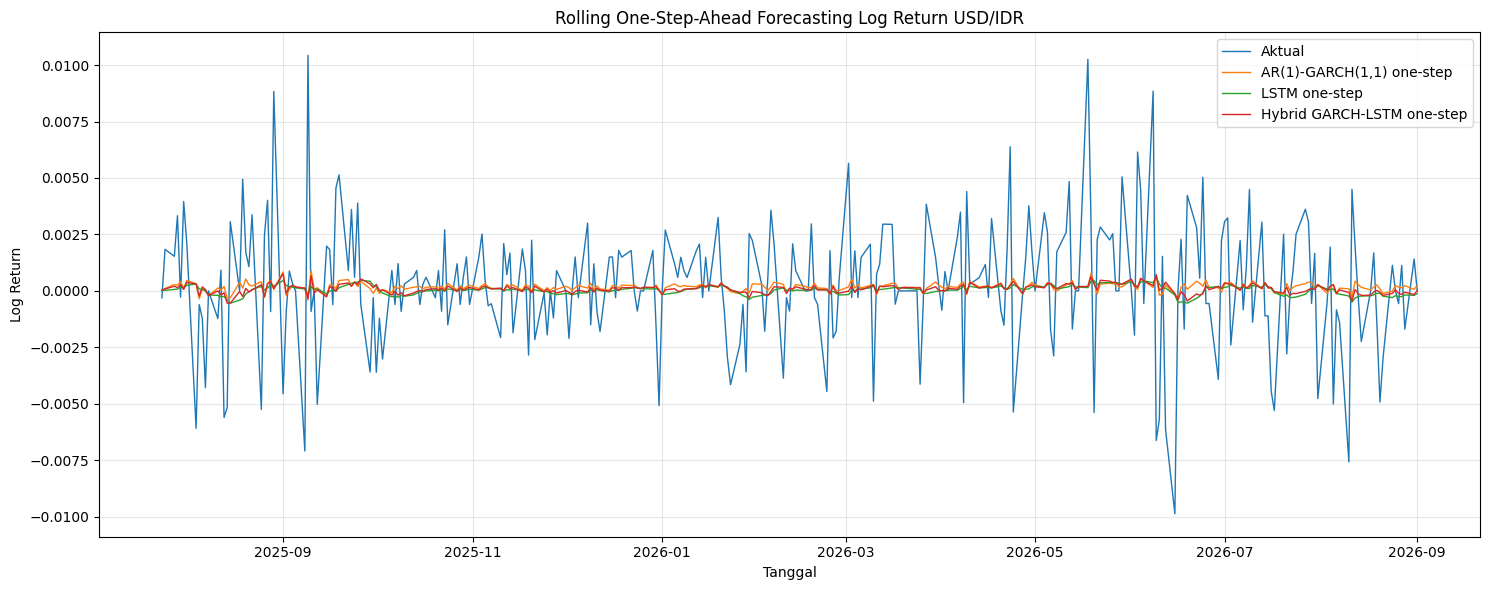

In [11]:
plt.figure(figsize=(15, 6))
plt.plot(hasil_forecast["Tanggal"], hasil_forecast["Aktual_Log_Return"],
         label="Aktual", linewidth=1.0)
plt.plot(hasil_forecast["Tanggal"], hasil_forecast["Prediksi_GARCH"],
         label="AR(1)-GARCH(1,1) one-step", linewidth=1.0)
plt.plot(hasil_forecast["Tanggal"], hasil_forecast["Prediksi_LSTM"],
         label="LSTM one-step", linewidth=1.0)
plt.plot(hasil_forecast["Tanggal"], hasil_forecast["Prediksi_Hybrid"],
         label="Hybrid GARCH-LSTM one-step", linewidth=1.0)
plt.title("Rolling One-Step-Ahead Forecasting Log Return USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("Log Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Evaluasi pada log return
MAPE tidak direkomendasikan untuk log return karena nilai return bisa nol atau sangat dekat nol. Gunakan MSE, RMSE, dan MAE untuk evaluasi return.

In [12]:
aktual_return = r_test_np
prediksi_return_dict = {
    "AR(1)-GARCH(1,1)": prediksi_garch,
    "LSTM": prediksi_lstm,
    "Hybrid GARCH-LSTM": prediksi_hybrid
}

rows = []
for nama, pred in prediksi_return_dict.items():
    mse = mean_squared_error(aktual_return, pred)
    rows.append({
        "Model": nama,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(aktual_return, pred)
    })

evaluasi_return = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(evaluasi_return)

,Model,MSE,RMSE,MAE
0,"AR(1)-GARCH(1,1)",0.000008,0.002830,0.002069
1,LSTM,0.000008,0.002841,0.002092
2,Hybrid GARCH-LSTM,0.000008,0.002842,0.002084


## 11. Rekonstruksi harga dengan one-step-ahead

Untuk harga kurs, gunakan:
\[
\widehat{P}_t = P_{t-1}\exp(\widehat{r}_t)
\]

Di sini `P_(t-1)` adalah **harga aktual periode sebelumnya yang sudah tersedia**. Jangan menggunakan satu harga awal untuk mengakumulasikan seluruh return prediksi, karena itu akan mengubah tugas menjadi prediksi multi-step rekursif.

In [13]:
harga_aktual = test["Kurs"].to_numpy(dtype=float)

# Harga aktual periode sebelumnya: harga terakhir training, lalu harga aktual test sebelumnya
harga_sebelumnya = data_return["Kurs"].iloc[batas - 1:-1].to_numpy(dtype=float)

if not (len(harga_sebelumnya) == len(harga_aktual) == len(prediksi_garch)):
    raise ValueError(
        f"Panjang array tidak sama: sebelumnya={len(harga_sebelumnya)}, "
        f"aktual={len(harga_aktual)}, prediksi={len(prediksi_garch)}"
    )

harga_garch = harga_sebelumnya * np.exp(prediksi_garch)
harga_lstm = harga_sebelumnya * np.exp(prediksi_lstm)
harga_hybrid = harga_sebelumnya * np.exp(prediksi_hybrid)

hasil_harga = pd.DataFrame({
    "Tanggal": test["Tanggal"].to_numpy(),
    "Harga_Sebelumnya_Aktual": harga_sebelumnya,
    "Harga_Aktual": harga_aktual,
    "Prediksi_Harga_GARCH": harga_garch,
    "Prediksi_Harga_LSTM": harga_lstm,
    "Prediksi_Harga_Hybrid": harga_hybrid
})
display(hasil_harga.head(10))

,Tanggal,Harga_Sebelumnya_Aktual,Harga_Aktual,Prediksi_Harga_GARCH,Prediksi_Harga_LSTM,Prediksi_Harga_Hybrid
0,2025-07-24,16290.0,16285.0,16290.557215,16290.616506,16290.417299
1,2025-07-25,16285.0,16315.0,16286.763595,16285.399641,16286.416201
2,2025-07-28,16315.0,16340.0,16319.614564,16316.092119,16318.334505
3,2025-07-29,16340.0,16394.5,16344.233669,16341.287922,16342.431029
4,2025-07-30,16394.5,16390.0,16401.190112,16397.289819,16399.120758
5,2025-07-31,16390.0,16455.0,16391.892708,16392.315939,16391.004585
6,2025-08-01,16455.0,16490.0,16462.574726,16459.106213,16461.275268
7,2025-08-04,16490.0,16390.0,16495.192666,16495.052771,16495.031161
8,2025-08-05,16390.0,16380.0,16384.228662,16391.317460,16386.328710
9,2025-08-06,16380.0,16360.0,16381.425316,16381.111437,16382.898410


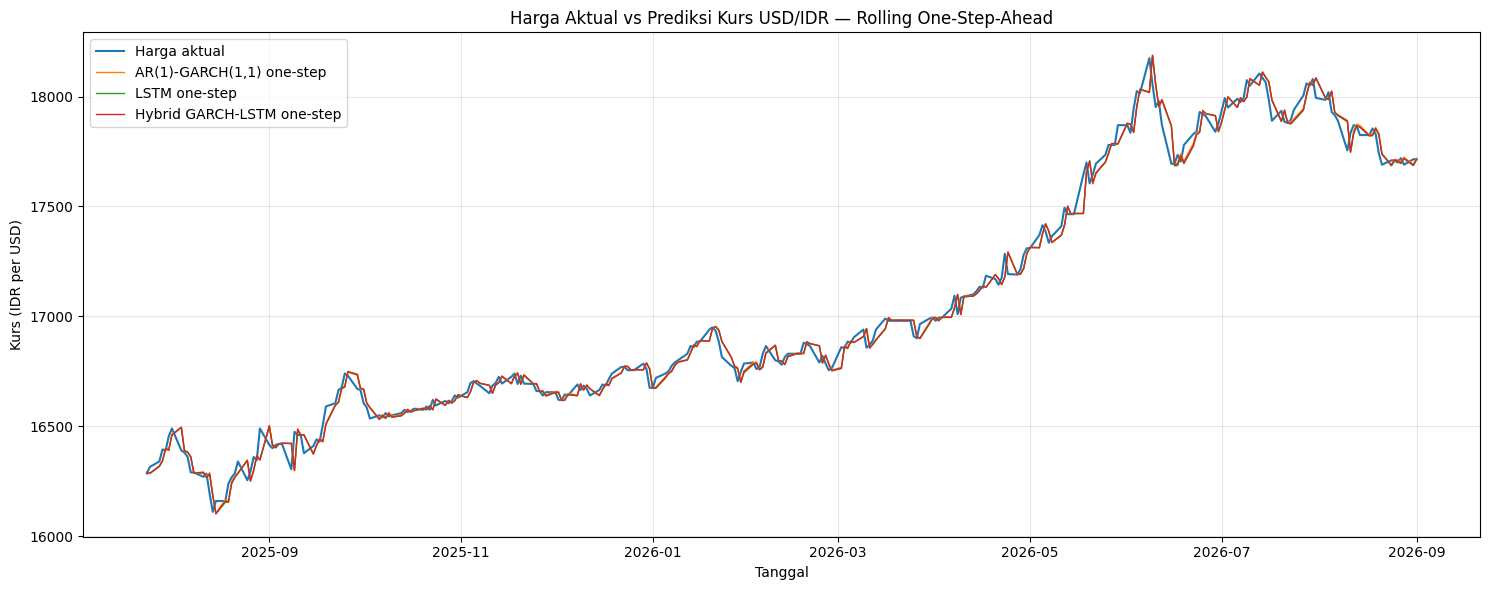

In [14]:
plt.figure(figsize=(15, 6))
plt.plot(hasil_harga["Tanggal"], hasil_harga["Harga_Aktual"],
         label="Harga aktual", linewidth=1.5)
plt.plot(hasil_harga["Tanggal"], hasil_harga["Prediksi_Harga_GARCH"],
         label="AR(1)-GARCH(1,1) one-step", linewidth=1.0)
plt.plot(hasil_harga["Tanggal"], hasil_harga["Prediksi_Harga_LSTM"],
         label="LSTM one-step", linewidth=1.0)
plt.plot(hasil_harga["Tanggal"], hasil_harga["Prediksi_Harga_Hybrid"],
         label="Hybrid GARCH-LSTM one-step", linewidth=1.0)
plt.title("Harga Aktual vs Prediksi Kurs USD/IDR — Rolling One-Step-Ahead")
plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Evaluasi harga kurs
MAPE digunakan pada harga kurs yang positif. Nilai terkecil menunjukkan kesalahan yang lebih rendah pada metrik tersebut.

In [15]:
def evaluasi_harga(aktual, prediksi):
    aktual = np.asarray(aktual, dtype=float)
    prediksi = np.asarray(prediksi, dtype=float)
    mse = mean_squared_error(aktual, prediksi)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(aktual, prediksi)
    mape = np.mean(np.abs((aktual - prediksi) / aktual)) * 100
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "MAPE (%)": mape}

evaluasi_harga_df = pd.DataFrame({
    "AR(1)-GARCH(1,1)": evaluasi_harga(harga_aktual, harga_garch),
    "LSTM": evaluasi_harga(harga_aktual, harga_lstm),
    "Hybrid GARCH-LSTM": evaluasi_harga(harga_aktual, harga_hybrid)
}).T.sort_values("RMSE")

display(evaluasi_harga_df)

,MSE,RMSE,MAE,MAPE (%)
"AR(1)-GARCH(1,1)",2365.489494,48.636298,35.426460,0.206852
LSTM,2384.388701,48.830203,35.821643,0.209164
Hybrid GARCH-LSTM,2385.209735,48.838609,35.692787,0.208430


## 13. Pemeriksaan variasi prediksi
Gunakan ini untuk melihat apakah prediksi terlalu dekat dengan nol dibandingkan variasi aktual.

In [16]:
ringkasan = pd.DataFrame({
    "Aktual": aktual_return,
    "GARCH": prediksi_garch,
    "LSTM": prediksi_lstm,
    "Hybrid": prediksi_hybrid
})
display(ringkasan.describe().T)

std_aktual = ringkasan["Aktual"].std()
print("Standar deviasi aktual:", std_aktual)
for nama in ["GARCH", "LSTM", "Hybrid"]:
    std_pred = ringkasan[nama].std()
    rasio = std_pred / std_aktual if std_aktual != 0 else np.nan
    print(f"{nama}: SD prediksi={std_pred:.8f}; rasio SD prediksi/aktual={rasio:.4f}")

,count,mean,std,min,25%,50%,75%,max
Aktual,289.0,0.000290,0.002817,-0.009869,-0.000899,0.000000,0.001840,0.010434
GARCH,289.0,0.000172,0.000187,-0.000420,0.000091,0.000170,0.000275,0.000890
LSTM,289.0,0.000036,0.000196,-0.000544,-0.000097,0.000060,0.000152,0.000610
Hybrid,289.0,0.000090,0.000193,-0.000545,-0.000026,0.000099,0.000197,0.000753


Standar deviasi aktual: 0.002816605658109673
GARCH: SD prediksi=0.00018672; rasio SD prediksi/aktual=0.0663
LSTM: SD prediksi=0.00019601; rasio SD prediksi/aktual=0.0696
Hybrid: SD prediksi=0.00019316; rasio SD prediksi/aktual=0.0686


## Catatan metodologis penting

- Semua model memprediksi **log return**, bukan langsung harga kurs.
- Forecasting dilakukan secara rolling one-step-ahead dengan data aktual terbaru hanya ditambahkan **setelah** prediksi untuk periode tersebut dibuat.
- Untuk harga kurs, prediksi satu langkah menggunakan harga aktual periode sebelumnya. Oleh sebab itu, grafik harga one-step-ahead bisa tampak dekat dengan aktual; evaluasi return tetap penting.
- Model hybrid di sini menggunakan LSTM untuk memprediksi koreksi residual. Residual pada testing diperbarui dengan kesalahan ramalan GARCH yang telah teramati.
- Jangan menyimpulkan hybrid paling bagus sebelum melihat metrik testing. Jika GARCH lebih baik, laporkan hasil tersebut apa adanya.
- Estimasi ulang GARCH pada setiap periode testing memang lebih lambat. Ini dilakukan agar prediksi mengikuti skema expanding-window one-step-ahead.

In [50]:
# ============================================================
# ROLLING ONE-STEP-AHEAD FORECAST
# SELURUH DATA HISTORIS SETELAH TRAINING
# AR(1)-GARCH(1,1), LSTM, DAN HYBRID GARCH-LSTM
# ============================================================

# ------------------------------------------------------------
# 1. MENYIAPKAN DATA
# ------------------------------------------------------------

r_historis = data_return["Log_Return"].astype(float).to_numpy()
tanggal_historis = data_return["Tanggal"].to_numpy()
harga_historis = data_return["Kurs"].astype(float).to_numpy()

r_historis_pct = 100.0 * r_historis

# Mulai forecasting setelah periode training
start = len(train)

# Riwayat return yang sudah tersedia pada awal forecasting
history_return_pct = list(r_historis_pct[:start])

# Residual training dari model AR(1)-GARCH
history_resid_pct = list(residual_train_pct[:, 0])

# Menampung hasil prediksi
prediksi_garch_historis_pct = []
prediksi_lstm_historis_pct = []
prediksi_resid_historis_pct = []
prediksi_hybrid_historis_pct = []

# Menampung tanggal aktual yang diprediksi
tanggal_forecast_historis = []

# Menampung harga aktual dan harga sebelumnya
harga_aktual_historis = []
harga_sebelumnya_historis = []


# ------------------------------------------------------------
# 2. ROLLING ONE-STEP-AHEAD
# ------------------------------------------------------------

for i in range(start, len(data_return)):

    # ========================================================
    # A. AR(1)-GARCH(1,1)
    # Menggunakan seluruh return yang tersedia sebelum target
    # ========================================================

    returns_available_pct = np.asarray(
        r_historis_pct[:i],
        dtype=float
    )

    model_roll = arch_model(
        returns_available_pct,
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    hasil_roll = model_roll.fit(
        disp="off",
        show_warning=False
    )

    forecast_roll = hasil_roll.forecast(
        horizon=1,
        method="analytic",
        reindex=False
    )

    forecast_garch_pct = float(
        forecast_roll.mean.iloc[-1, 0]
    )

    prediksi_garch_historis_pct.append(
        forecast_garch_pct
    )


    # ========================================================
    # B. LSTM
    # Menggunakan LOOKBACK return aktual terakhir yang tersedia
    # ========================================================

    x_return_pct = np.asarray(
        history_return_pct[-LOOKBACK:],
        dtype=float
    ).reshape(-1, 1)

    x_return_scaled = scaler_return.transform(
        x_return_pct
    )

    x_lstm = x_return_scaled.reshape(
        1, LOOKBACK, 1
    )

    pred_lstm_scaled = float(
        model_lstm.predict(
            x_lstm,
            verbose=0
        )[0, 0]
    )

    forecast_lstm_pct = float(
        scaler_return.inverse_transform(
            np.array([[pred_lstm_scaled]])
        )[0, 0]
    )

    prediksi_lstm_historis_pct.append(
        forecast_lstm_pct
    )


    # ========================================================
    # C. LSTM RESIDUAL UNTUK MODEL HYBRID
    # ========================================================

    x_resid_pct = np.asarray(
        history_resid_pct[-LOOKBACK_RESID:],
        dtype=float
    ).reshape(-1, 1)

    x_resid_scaled = scaler_resid.transform(
        x_resid_pct
    )

    x_hybrid = x_resid_scaled.reshape(
        1, LOOKBACK_RESID, 1
    )

    pred_resid_scaled = float(
        model_resid_lstm.predict(
            x_hybrid,
            verbose=0
        )[0, 0]
    )

    forecast_resid_pct = float(
        scaler_resid.inverse_transform(
            np.array([[pred_resid_scaled]])
        )[0, 0]
    )

    prediksi_resid_historis_pct.append(
        forecast_resid_pct
    )


    # ========================================================
    # D. HYBRID GARCH-LSTM
    # Prediksi GARCH + koreksi residual LSTM
    # ========================================================

    forecast_hybrid_pct = (
        forecast_garch_pct + forecast_resid_pct
    )

    prediksi_hybrid_historis_pct.append(
        forecast_hybrid_pct
    )


    # ========================================================
    # E. MENAMBAHKAN AKTUAL SETELAH PREDIKSI DIBUAT
    # ========================================================

    actual_i_pct = r_historis_pct[i]

    history_return_pct.append(
        actual_i_pct
    )

    # Residual GARCH yang sudah teramati
    resid_observed_pct = (
        actual_i_pct - forecast_garch_pct
    )

    history_resid_pct.append(
        resid_observed_pct
    )


    # ========================================================
    # F. MENYIMPAN INFORMASI PERIODE
    # ========================================================

    tanggal_forecast_historis.append(
        tanggal_historis[i]
    )

    harga_aktual_historis.append(
        harga_historis[i]
    )

    harga_sebelumnya_historis.append(
        harga_historis[i - 1]
    )


    # Menampilkan progres
    jumlah_selesai = i - start + 1
    jumlah_total = len(data_return) - start

    if jumlah_selesai % 50 == 0 or jumlah_selesai == jumlah_total:
        print(
            f"Progres: {jumlah_selesai}/{jumlah_total}"
        )


# ------------------------------------------------------------
# 3. MENGEMBALIKAN PREDIKSI KE SKALA LOG RETURN
# ------------------------------------------------------------

prediksi_garch_historis = (
    np.asarray(prediksi_garch_historis_pct) / 100.0
)

prediksi_lstm_historis = (
    np.asarray(prediksi_lstm_historis_pct) / 100.0
)

prediksi_resid_historis = (
    np.asarray(prediksi_resid_historis_pct) / 100.0
)

prediksi_hybrid_historis = (
    np.asarray(prediksi_hybrid_historis_pct) / 100.0
)


# ------------------------------------------------------------
# 4. REKONSTRUKSI PREDIKSI HARGA KURS
# P_t = P_(t-1) * exp(prediksi log return)
# ------------------------------------------------------------

harga_sebelumnya_historis = np.asarray(
    harga_sebelumnya_historis,
    dtype=float
)

harga_aktual_historis = np.asarray(
    harga_aktual_historis,
    dtype=float
)

harga_garch_historis = (
    harga_sebelumnya_historis
    * np.exp(prediksi_garch_historis)
)

harga_lstm_historis = (
    harga_sebelumnya_historis
    * np.exp(prediksi_lstm_historis)
)

harga_hybrid_historis = (
    harga_sebelumnya_historis
    * np.exp(prediksi_hybrid_historis)
)


# ------------------------------------------------------------
# 5. MEMBUAT TABEL HASIL FORECASTING
# ------------------------------------------------------------

hasil_forecast_historis = pd.DataFrame({
    "Tanggal": tanggal_forecast_historis,
    "Harga_Aktual": harga_aktual_historis,
    "Prediksi_GARCH": harga_garch_historis,
    "Prediksi_LSTM": harga_lstm_historis,
    "Prediksi_Hybrid": harga_hybrid_historis,
    "Aktual_Log_Return": r_historis[start:],
    "Prediksi_Log_Return_GARCH": prediksi_garch_historis,
    "Prediksi_Log_Return_LSTM": prediksi_lstm_historis,
    "Prediksi_Log_Return_Hybrid": prediksi_hybrid_historis
})

display(hasil_forecast_historis.head(10))

print(
    "Jumlah observasi yang diprediksi:",
    len(hasil_forecast_historis)
)

Progres: 50/289
Progres: 100/289
Progres: 150/289
Progres: 200/289
Progres: 250/289
Progres: 289/289


,Tanggal,Harga_Aktual,Prediksi_GARCH,Prediksi_LSTM,Prediksi_Hybrid,Aktual_Log_Return,Prediksi_Log_Return_GARCH,Prediksi_Log_Return_LSTM,Prediksi_Log_Return_Hybrid
0,2025-07-24,16285.0,16290.557215,16290.616506,16290.417299,-0.000307,0.000034,0.000038,0.000026
1,2025-07-25,16315.0,16286.763595,16285.399641,16286.416201,0.001840,0.000108,0.000025,0.000087
2,2025-07-28,16340.0,16319.614564,16316.092119,16318.334505,0.001531,0.000283,0.000067,0.000204
3,2025-07-29,16394.5,16344.233669,16341.287922,16342.431029,0.003330,0.000259,0.000079,0.000149
4,2025-07-30,16390.0,16401.190112,16397.289819,16399.120758,-0.000275,0.000408,0.000170,0.000282
5,2025-07-31,16455.0,16391.892708,16392.315939,16391.004585,0.003958,0.000115,0.000141,0.000061
6,2025-08-01,16490.0,16462.574726,16459.106213,16461.275268,0.002125,0.000460,0.000250,0.000381
7,2025-08-04,16390.0,16495.192666,16495.052771,16495.031161,-0.006083,0.000315,0.000306,0.000305
8,2025-08-05,16380.0,16384.228662,16391.317460,16386.328710,-0.000610,-0.000352,0.000080,-0.000224
9,2025-08-06,16360.0,16381.425316,16381.111437,16382.898410,-0.001222,0.000087,0.000068,0.000177


Jumlah observasi yang diprediksi: 289


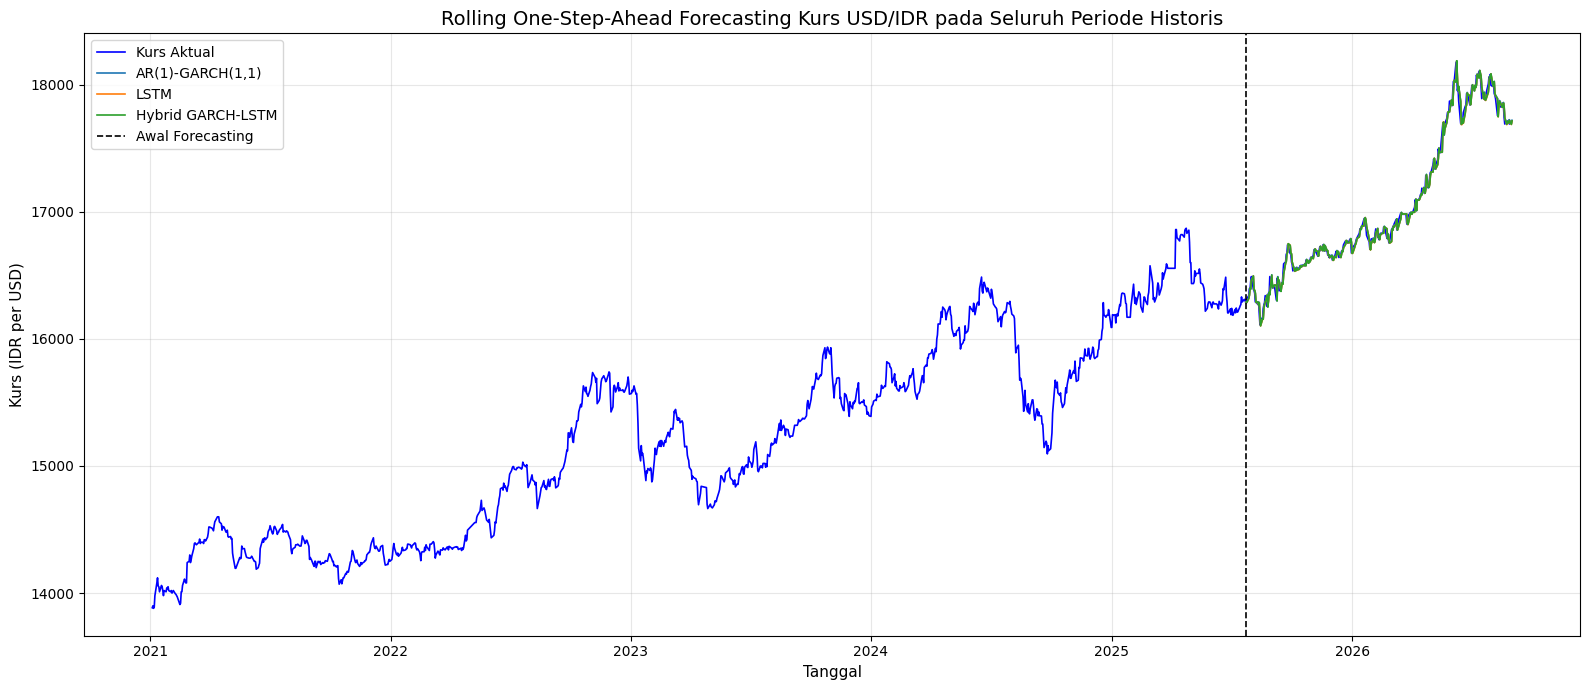

In [51]:
import matplotlib.pyplot as plt

# ==========================================
# PLOT ROLLING ONE-STEP-AHEAD FORECASTING
# ==========================================

plt.figure(figsize=(16, 7))

# 1. Data kurs aktual seluruh periode
plt.plot(
    data_return["Tanggal"],
    data_return["Kurs"],
    label="Kurs Aktual",
    color="blue",
    linewidth=1.2
)

# 2. Prediksi AR(1)-GARCH(1,1)
plt.plot(
    hasil_forecast_historis["Tanggal"],
    hasil_forecast_historis["Prediksi_GARCH"],
    label="AR(1)-GARCH(1,1)",
    linewidth=1.2
)

# 3. Prediksi LSTM
plt.plot(
    hasil_forecast_historis["Tanggal"],
    hasil_forecast_historis["Prediksi_LSTM"],
    label="LSTM",
    linewidth=1.2
)

# 4. Prediksi Hybrid GARCH-LSTM
plt.plot(
    hasil_forecast_historis["Tanggal"],
    hasil_forecast_historis["Prediksi_Hybrid"],
    label="Hybrid GARCH-LSTM",
    linewidth=1.2
)

# 5. Garis batas awal forecasting
tanggal_awal = hasil_forecast_historis["Tanggal"].iloc[0]

plt.axvline(
    x=tanggal_awal,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Awal Forecasting"
)

# 6. Pengaturan grafik
plt.title(
    "Rolling One-Step-Ahead Forecasting Kurs USD/IDR "
    "pada Seluruh Periode Historis",
    fontsize=14
)

plt.xlabel("Tanggal", fontsize=11)
plt.ylabel("Kurs (IDR per USD)", fontsize=11)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

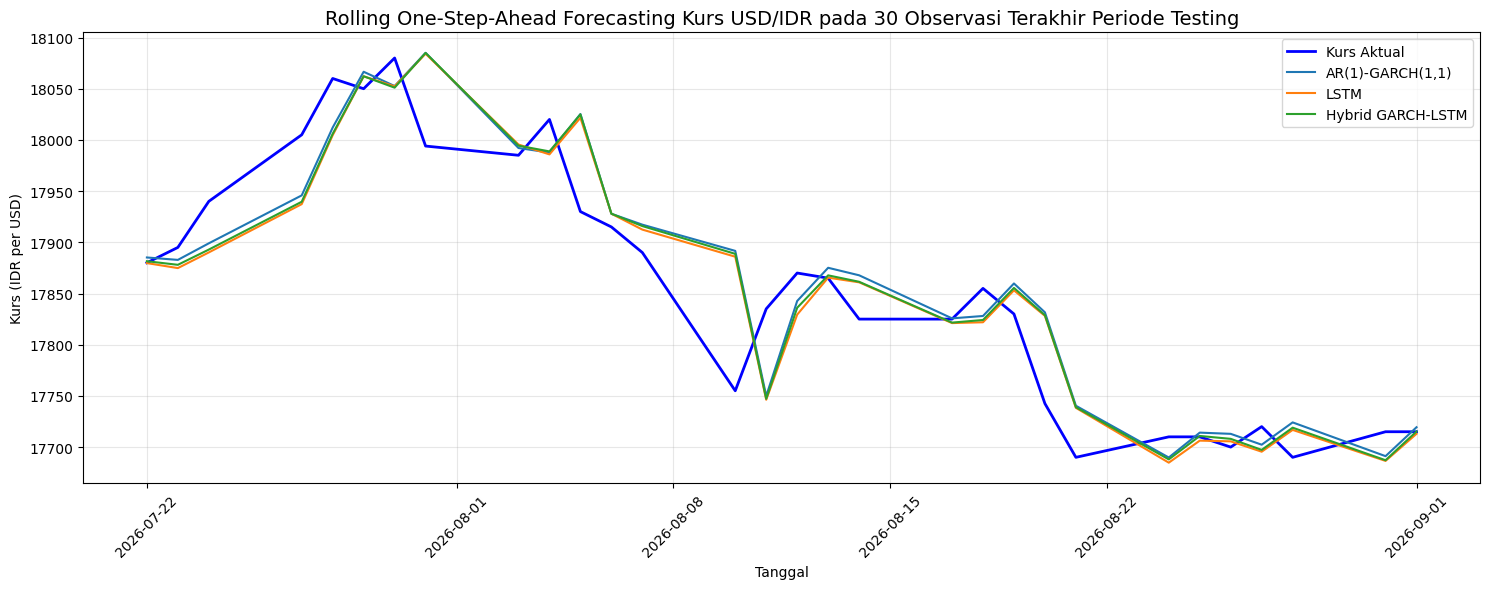

In [53]:

# ============================================================
# PLOT ROLLING ONE-STEP-AHEAD FORECASTING
# 30 OBSERVASI TERAKHIR PERIODE TESTING
# AR(1)-GARCH(1,1), LSTM, DAN HYBRID GARCH-LSTM
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. MENGAMBIL 30 OBSERVASI TERAKHIR
# ------------------------------------------------------------

hasil_plot = hasil_forecast_historis.tail(30).copy()

hasil_plot["Tanggal"] = pd.to_datetime(
    hasil_plot["Tanggal"]
)

# ------------------------------------------------------------
# 2. PLOT HARGA KURS AKTUAL DAN HASIL FORECASTING
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    hasil_plot["Tanggal"],
    hasil_plot["Harga_Aktual"],
    label="Kurs Aktual",
    color="blue",
    linewidth=2
)

plt.plot(
    hasil_plot["Tanggal"],
    hasil_plot["Prediksi_GARCH"],
    label="AR(1)-GARCH(1,1)",
    linewidth=1.5
)

plt.plot(
    hasil_plot["Tanggal"],
    hasil_plot["Prediksi_LSTM"],
    label="LSTM",
    linewidth=1.5
)

plt.plot(
    hasil_plot["Tanggal"],
    hasil_plot["Prediksi_Hybrid"],
    label="Hybrid GARCH-LSTM",
    linewidth=1.5
)

# ------------------------------------------------------------
# 3. PENGATURAN GRAFIK
# ------------------------------------------------------------

plt.title(
    "Rolling One-Step-Ahead Forecasting Kurs USD/IDR "
    "pada 30 Observasi Terakhir Periode Testing",
    fontsize=14
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Tanggal historis terakhir : 2026-09-01
Tanggal awal forecasting  : 2026-09-02
Jumlah periode forecasting: 30
Jumlah residual training: 1151
Jumlah residual testing : 289
Jumlah residual awal Hybrid: 1440

TABEL FORECASTING 30 PERIODE


,Tanggal,Prediksi_Log_Return_GARCH,Prediksi_Log_Return_LSTM,Prediksi_Log_Return_Hybrid,Prediksi_Harga_GARCH,Prediksi_Harga_LSTM,Prediksi_Harga_Hybrid
0,2026-09-02,0.000165,-0.000109,-0.000047,17717.921489,17713.065083,17714.162171
1,2026-09-03,0.000174,-0.000076,0.000008,17721.011567,17711.712307,17714.310446
2,2026-09-04,0.000175,-0.000033,0.000059,17724.108967,17711.131143,17715.348974
3,2026-09-07,0.000175,-0.000014,0.000078,17727.204203,17710.884702,17716.729949
4,2026-09-08,0.000174,-0.000024,0.000068,17730.296829,17710.457723,17717.934407
5,2026-09-09,0.000174,-0.000026,0.000069,17733.386833,17710.001075,17719.155460
6,2026-09-10,0.000174,-0.000024,0.000072,17736.474200,17709.569985,17720.432455
7,2026-09-11,0.000174,-0.000033,0.000065,17739.558948,17708.987396,17721.578778
8,2026-09-14,0.000174,-0.000024,0.000076,17742.641092,17708.563936,17722.918436
9,2026-09-15,0.000174,-0.000035,0.000065,17745.720709,17707.947133,17724.064468


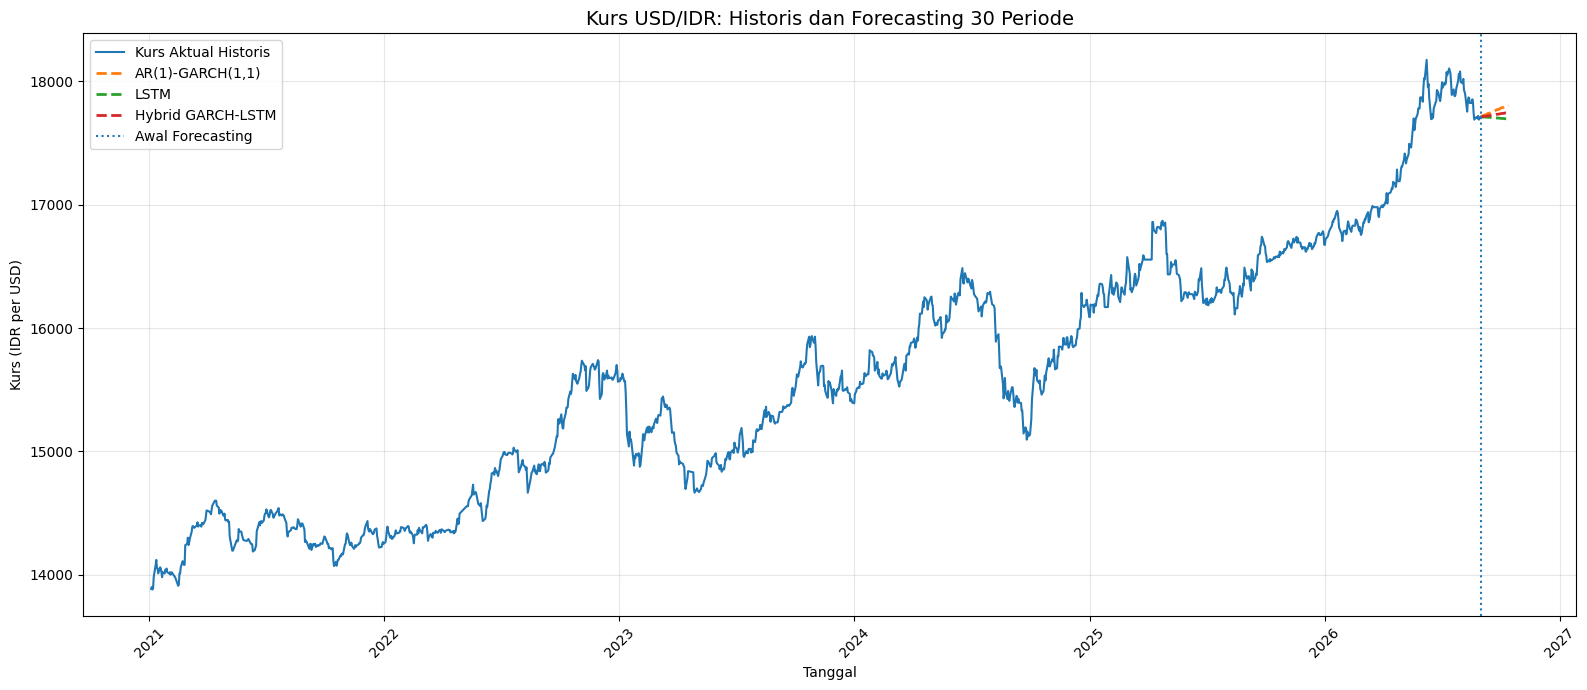

In [59]:
# ============================================================
# FORECASTING 30 PERIODE SETELAH SELURUH DATA HISTORIS
# AR(1)-GARCH(1,1), LSTM, DAN HYBRID GARCH-LSTM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from arch import arch_model


# ============================================================
# 1. MENYIAPKAN DATA HISTORIS
# ============================================================

data_hist = data_return.copy()

data_hist["Tanggal"] = pd.to_datetime(data_hist["Tanggal"])
data_hist = data_hist.sort_values("Tanggal").reset_index(drop=True)

tanggal_hist = data_hist["Tanggal"]
harga_hist = data_hist["Kurs"].astype(float).to_numpy()
return_hist = data_hist["Log_Return"].astype(float).to_numpy()

# GARCH menggunakan log return dalam skala persen
return_hist_pct = return_hist * 100.0

HORIZON = 30

tanggal_terakhir = tanggal_hist.iloc[-1]
harga_terakhir = float(harga_hist[-1])

tanggal_future = pd.bdate_range(
    start=tanggal_terakhir + pd.Timedelta(days=1),
    periods=HORIZON
)

print("Tanggal historis terakhir :", tanggal_terakhir.date())
print("Tanggal awal forecasting  :", tanggal_future[0].date())
print("Jumlah periode forecasting:", HORIZON)


# ============================================================
# 2. MENYIAPKAN RESIDUAL TRAINING DAN TESTING UNTUK HYBRID
# ============================================================

# Residual training dari model GARCH yang sebelumnya dilatih
resid_train = np.asarray(
    residual_train_pct,
    dtype=float
).reshape(-1)

# Jika tabel rolling forecasting tersedia dan kolomnya sesuai,
# gunakan residual dari prediksi one-step-ahead periode testing.
resid_test = None

if (
    "hasil_forecast_historis" in globals()
    and isinstance(hasil_forecast_historis, pd.DataFrame)
    and "Aktual_Log_Return" in hasil_forecast_historis.columns
    and "Prediksi_Log_Return_GARCH" in hasil_forecast_historis.columns
    and len(hasil_forecast_historis) == len(test)
):
    resid_test = (
        hasil_forecast_historis["Aktual_Log_Return"].to_numpy(dtype=float)
        - hasil_forecast_historis["Prediksi_Log_Return_GARCH"].to_numpy(dtype=float)
    ) * 100.0

else:
    # Jika tabel rolling tidak tersedia, hitung residual testing
    # menggunakan GARCH expanding-window satu langkah ke depan.
    # Setiap prediksi dibuat sebelum nilai aktual testing dimasukkan.

    resid_test_list = []

    history_for_resid = (
        train["Log_Return"].astype(float).to_numpy() * 100.0
    ).tolist()

    for actual_return in test["Log_Return"].astype(float).to_numpy():

        model_roll = arch_model(
            np.asarray(history_for_resid, dtype=float),
            mean="AR",
            lags=1,
            vol="GARCH",
            p=1,
            q=1,
            dist="normal",
            rescale=False
        )

        fit_roll = model_roll.fit(
            disp="off",
            show_warning=False
        )

        pred_roll = float(
            fit_roll.forecast(
                horizon=1,
                reindex=False
            ).mean.iloc[-1, 0]
        )

        actual_return_pct = float(actual_return) * 100.0

        resid_test_list.append(
            actual_return_pct - pred_roll
        )

        # Nilai aktual baru dimasukkan setelah prediksi dibuat
        history_for_resid.append(actual_return_pct)

    resid_test = np.asarray(resid_test_list, dtype=float)


# Gabungkan residual training dan testing
history_resid_pct = np.concatenate([
    resid_train,
    resid_test
]).astype(float).tolist()

print("Jumlah residual training:", len(resid_train))
print("Jumlah residual testing :", len(resid_test))
print("Jumlah residual awal Hybrid:", len(history_resid_pct))


# ============================================================
# 3. MEMBUAT RIWAYAT INPUT TERPISAH UNTUK SETIAP MODEL
# ============================================================

# Masing-masing model mempunyai riwayat prediksinya sendiri.
history_garch_pct = list(return_hist_pct)
history_lstm_pct = list(return_hist_pct)

prediksi_garch_pct = []
prediksi_lstm_pct = []
prediksi_residual_pct = []
prediksi_hybrid_pct = []


# ============================================================
# 4. FORECASTING REKURSIF SATU LANGKAH KE DEPAN
# ============================================================

for i in range(HORIZON):

    # --------------------------------------------------------
    # A. AR(1)-GARCH(1,1)
    # --------------------------------------------------------

    model_garch = arch_model(
        np.asarray(history_garch_pct, dtype=float),
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    fit_garch = model_garch.fit(
        disp="off",
        show_warning=False
    )

    pred_garch = float(
        fit_garch.forecast(
            horizon=1,
            method="analytic",
            reindex=False
        ).mean.iloc[-1, 0]
    )

    prediksi_garch_pct.append(pred_garch)


    # --------------------------------------------------------
    # B. LSTM
    # --------------------------------------------------------

    x_lstm_pct = np.asarray(
        history_lstm_pct[-LOOKBACK:],
        dtype=float
    ).reshape(-1, 1)

    x_lstm_scaled = scaler_return.transform(x_lstm_pct)

    x_lstm = x_lstm_scaled.reshape(1, LOOKBACK, 1)

    pred_lstm_scaled = float(
        model_lstm.predict(
            x_lstm,
            verbose=0
        )[0, 0]
    )

    pred_lstm = float(
        scaler_return.inverse_transform(
            np.array([[pred_lstm_scaled]])
        )[0, 0]
    )

    prediksi_lstm_pct.append(pred_lstm)


    # --------------------------------------------------------
    # C. LSTM RESIDUAL UNTUK HYBRID
    # --------------------------------------------------------

    x_resid_pct = np.asarray(
        history_resid_pct[-LOOKBACK_RESID:],
        dtype=float
    ).reshape(-1, 1)

    x_resid_scaled = scaler_resid.transform(x_resid_pct)

    x_resid = x_resid_scaled.reshape(
        1, LOOKBACK_RESID, 1
    )

    pred_resid_scaled = float(
        model_resid_lstm.predict(
            x_resid,
            verbose=0
        )[0, 0]
    )

    pred_resid = float(
        scaler_resid.inverse_transform(
            np.array([[pred_resid_scaled]])
        )[0, 0]
    )

    prediksi_residual_pct.append(pred_resid)


    # --------------------------------------------------------
    # D. HYBRID GARCH-LSTM
    # --------------------------------------------------------

    pred_hybrid = pred_garch + pred_resid

    prediksi_hybrid_pct.append(pred_hybrid)


    # --------------------------------------------------------
    # E. MEMPERBARUI INPUT UNTUK PERIODE BERIKUTNYA
    # --------------------------------------------------------

    # GARCH memakai prediksi GARCH sebelumnya
    history_garch_pct.append(pred_garch)

    # LSTM memakai prediksi LSTM sebelumnya
    history_lstm_pct.append(pred_lstm)

    # Hybrid memakai prediksi residual sebelumnya
    history_resid_pct.append(pred_resid)


# ============================================================
# 5. MENGEMBALIKAN LOG RETURN KE SKALA ASLI
# ============================================================

prediksi_garch = np.asarray(prediksi_garch_pct) / 100.0
prediksi_lstm = np.asarray(prediksi_lstm_pct) / 100.0
prediksi_residual = np.asarray(prediksi_residual_pct) / 100.0
prediksi_hybrid = np.asarray(prediksi_hybrid_pct) / 100.0


# ============================================================
# 6. REKONSTRUKSI KURS DARI PREDIKSI LOG RETURN
# ============================================================

harga_garch = []
harga_lstm = []
harga_hybrid = []

p_garch = harga_terakhir
p_lstm = harga_terakhir
p_hybrid = harga_terakhir

for i in range(HORIZON):

    p_garch = p_garch * np.exp(prediksi_garch[i])
    p_lstm = p_lstm * np.exp(prediksi_lstm[i])
    p_hybrid = p_hybrid * np.exp(prediksi_hybrid[i])

    harga_garch.append(p_garch)
    harga_lstm.append(p_lstm)
    harga_hybrid.append(p_hybrid)


# ============================================================
# 7. TABEL HASIL FORECASTING
# ============================================================

hasil_forecast_future = pd.DataFrame({
    "Tanggal": tanggal_future,
    "Prediksi_Log_Return_GARCH": prediksi_garch,
    "Prediksi_Log_Return_LSTM": prediksi_lstm,
    "Prediksi_Log_Return_Hybrid": prediksi_hybrid,
    "Prediksi_Harga_GARCH": harga_garch,
    "Prediksi_Harga_LSTM": harga_lstm,
    "Prediksi_Harga_Hybrid": harga_hybrid
})

print("\nTABEL FORECASTING 30 PERIODE")
display(hasil_forecast_future)


# ============================================================
# 8. GRAFIK SELURUH HISTORIS DILANJUTKAN FORECASTING
# ============================================================

# Tambahkan titik kurs aktual terakhir sebagai titik sambungan
tanggal_garis = pd.DatetimeIndex(
    [tanggal_terakhir]
).append(pd.DatetimeIndex(tanggal_future))

garis_garch = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_garch)
])

garis_lstm = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_lstm)
])

garis_hybrid = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_hybrid)
])

plt.figure(figsize=(16, 7))

# Seluruh kurs aktual historis
plt.plot(
    tanggal_hist,
    harga_hist,
    label="Kurs Aktual Historis",
    linewidth=1.5
)

# Forecast ketiga model
plt.plot(
    tanggal_garis,
    garis_garch,
    linestyle="--",
    linewidth=2,
    label="AR(1)-GARCH(1,1)"
)

plt.plot(
    tanggal_garis,
    garis_lstm,
    linestyle="--",
    linewidth=2,
    label="LSTM"
)

plt.plot(
    tanggal_garis,
    garis_hybrid,
    linestyle="--",
    linewidth=2,
    label="Hybrid GARCH-LSTM"
)

plt.axvline(
    tanggal_terakhir,
    linestyle=":",
    linewidth=1.5,
    label="Awal Forecasting"
)

plt.title(
    "Kurs USD/IDR: Historis dan Forecasting 30 Periode",
    fontsize=14
)

plt.xlabel("Tanggal")
plt.ylabel("Kurs (IDR per USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [61]:
# ============================================================
# ROLLING ONE-STEP-AHEAD PADA DATA TESTING
# SIMPAN HASIL DALAM DATAFRAME
# ============================================================

hasil_rolling = []

history_return_pct = (
    train["Log_Return"].astype(float).to_numpy() * 100
).tolist()

for i in range(len(test)):

    # Data aktual yang tersedia sebelum periode target
    model_roll = arch_model(
        np.asarray(history_return_pct, dtype=float),
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    fit_roll = model_roll.fit(
        disp="off",
        show_warning=False
    )

    forecast_roll = fit_roll.forecast(
        horizon=1,
        reindex=False
    )

    prediksi_pct = float(
        forecast_roll.mean.iloc[-1, 0]
    )

    prediksi_return = prediksi_pct / 100

    aktual_return = float(
        test["Log_Return"].iloc[i]
    )

    # Simpan aktual, prediksi, dan residual
    hasil_rolling.append({
        "Tanggal": test["Tanggal"].iloc[i],
        "Aktual_Log_Return": aktual_return,
        "Prediksi_Log_Return_GARCH": prediksi_return,
        "Residual_GARCH": aktual_return - prediksi_return
    })

    # Aktual baru dimasukkan setelah prediksi dibuat
    history_return_pct.append(
        aktual_return * 100
    )


# Simpan sebagai DataFrame
hasil_forecast_historis = pd.DataFrame(
    hasil_rolling
)

display(hasil_forecast_historis)

,Tanggal,Aktual_Log_Return,Prediksi_Log_Return_GARCH,Residual_GARCH
0,2025-07-24,-0.000307,0.000034,-0.000341
1,2025-07-25,0.001840,0.000108,0.001732
2,2025-07-28,0.001531,0.000283,0.001248
3,2025-07-29,0.003330,0.000259,0.003071
4,2025-07-30,-0.000275,0.000408,-0.000683
...,...,...,...,...
284,2026-08-26,-0.000565,0.000166,-0.000731
285,2026-08-27,0.001129,0.000132,0.000997
286,2026-08-28,-0.001694,0.000232,-0.001927
287,2026-08-31,0.001412,0.000065,0.001348


In [62]:
# ============================================================
# FORECASTING 30 PERIODE SETELAH SELURUH DATA HISTORIS
# AR(1)-GARCH(1,1), LSTM, DAN HYBRID GARCH-LSTM
# Pendekatan rekursif satu langkah ke depan
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model


# ============================================================
# 1. MENYIAPKAN SELURUH DATA HISTORIS
# ============================================================

data_hist = data_return.copy()

data_hist["Tanggal"] = pd.to_datetime(data_hist["Tanggal"])
data_hist = data_hist.sort_values("Tanggal").reset_index(drop=True)

tanggal_hist = data_hist["Tanggal"]
harga_hist = data_hist["Kurs"].astype(float).to_numpy()
return_hist = data_hist["Log_Return"].astype(float).to_numpy()

# Return dalam skala persen, sesuai proses pelatihan model
return_hist_pct = 100.0 * return_hist

HORIZON = 30

tanggal_terakhir = tanggal_hist.iloc[-1]
harga_terakhir = float(harga_hist[-1])

tanggal_future = pd.bdate_range(
    start=tanggal_terakhir + pd.Timedelta(days=1),
    periods=HORIZON
)

print("Tanggal historis terakhir :", tanggal_terakhir.date())
print("Tanggal awal forecasting  :", tanggal_future[0].date())
print("Jumlah periode forecasting:", HORIZON)


# ============================================================
# 2. MENYIAPKAN RESIDUAL HISTORIS UNTUK HYBRID
# ============================================================

# Residual training dari model GARCH yang dilatih sebelumnya
resid_train = np.asarray(
    residual_train_pct,
    dtype=float
).reshape(-1)

# Residual testing dihitung dari hasil rolling one-step-ahead
# pada notebook, yaitu aktual dikurangi prediksi GARCH.
# Variabel hasil_forecast di sini adalah DataFrame pada bagian
# rolling one-step-ahead notebook, bukan objek .forecast() GARCH.

if not isinstance(globals().get("hasil_forecast"), pd.DataFrame):
    raise TypeError(
        "'hasil_forecast' bukan DataFrame rolling testing. "
        "Jalankan kembali bagian 8 notebook untuk membentuk "
        "DataFrame hasil_forecast sebelum menjalankan kode ini."
    )

kolom_wajib = [
    "Aktual_Log_Return",
    "Prediksi_GARCH"
]

if not all(
    kolom in hasil_forecast.columns
    for kolom in kolom_wajib
):
    raise ValueError(
        "DataFrame hasil_forecast belum memiliki kolom "
        "'Aktual_Log_Return' dan 'Prediksi_GARCH'."
    )

if len(hasil_forecast) != len(test):
    raise ValueError(
        "Jumlah baris hasil_forecast tidak sama dengan data testing. "
        "Periksa kembali hasil rolling one-step-ahead."
    )

resid_test = (
    hasil_forecast["Aktual_Log_Return"].to_numpy(dtype=float)
    - hasil_forecast["Prediksi_GARCH"].to_numpy(dtype=float)
) * 100.0

# Riwayat residual yang tersedia sampai akhir testing
history_resid_hybrid_pct = np.concatenate([
    resid_train,
    resid_test
]).astype(float).tolist()

print("Jumlah residual training:", len(resid_train))
print("Jumlah residual testing :", len(resid_test))
print(
    "Jumlah residual historis untuk Hybrid:",
    len(history_resid_hybrid_pct)
)


# ============================================================
# 3. MEMBUAT RIWAYAT RETURN TERPISAH UNTUK SETIAP MODEL
# ============================================================

# GARCH: riwayat return historis
history_garch_pct = list(return_hist_pct)

# LSTM: riwayat return historis
history_lstm_pct = list(return_hist_pct)

# Hybrid: riwayat return historis
history_hybrid_pct = list(return_hist_pct)


# ============================================================
# 4. MENYIAPKAN PENYIMPANAN HASIL FORECASTING
# ============================================================

prediksi_garch_pct_future = []
prediksi_lstm_pct_future = []
prediksi_resid_pct_future = []
prediksi_hybrid_pct_future = []


# ============================================================
# 5. FORECASTING REKURSIF 30 PERIODE
# ============================================================

for i in range(HORIZON):

    # --------------------------------------------------------
    # A. AR(1)-GARCH(1,1)
    # --------------------------------------------------------

    model_garch_future = arch_model(
        np.asarray(history_garch_pct, dtype=float),
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    fit_garch_future = model_garch_future.fit(
        disp="off",
        show_warning=False
    )

    forecast_garch = fit_garch_future.forecast(
        horizon=1,
        method="analytic",
        reindex=False
    )

    pred_garch_pct = float(
        forecast_garch.mean.iloc[-1, 0]
    )

    prediksi_garch_pct_future.append(
        pred_garch_pct
    )


    # --------------------------------------------------------
    # B. LSTM LOG RETURN
    # --------------------------------------------------------

    x_lstm_pct = np.asarray(
        history_lstm_pct[-LOOKBACK:],
        dtype=float
    ).reshape(-1, 1)

    x_lstm_scaled = scaler_return.transform(
        x_lstm_pct
    )

    x_lstm = x_lstm_scaled.reshape(
        1, LOOKBACK, 1
    )

    pred_lstm_scaled = float(
        model_lstm.predict(
            x_lstm,
            verbose=0
        )[0, 0]
    )

    pred_lstm_pct = float(
        scaler_return.inverse_transform(
            np.array([[pred_lstm_scaled]])
        )[0, 0]
    )

    prediksi_lstm_pct_future.append(
        pred_lstm_pct
    )


    # --------------------------------------------------------
    # C. LSTM RESIDUAL UNTUK HYBRID
    # --------------------------------------------------------

    x_resid_pct = np.asarray(
        history_resid_hybrid_pct[-LOOKBACK_RESID:],
        dtype=float
    ).reshape(-1, 1)

    x_resid_scaled = scaler_resid.transform(
        x_resid_pct
    )

    x_resid = x_resid_scaled.reshape(
        1, LOOKBACK_RESID, 1
    )

    pred_resid_scaled = float(
        model_resid_lstm.predict(
            x_resid,
            verbose=0
        )[0, 0]
    )

    pred_resid_pct = float(
        scaler_resid.inverse_transform(
            np.array([[pred_resid_scaled]])
        )[0, 0]
    )

    prediksi_resid_pct_future.append(
        pred_resid_pct
    )


    # --------------------------------------------------------
    # D. KOMPONEN GARCH UNTUK HYBRID
    # --------------------------------------------------------

    # Estimasi GARCH menggunakan riwayat return Hybrid
    model_garch_hybrid = arch_model(
        np.asarray(history_hybrid_pct, dtype=float),
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    fit_garch_hybrid = model_garch_hybrid.fit(
        disp="off",
        show_warning=False
    )

    forecast_garch_hybrid = fit_garch_hybrid.forecast(
        horizon=1,
        method="analytic",
        reindex=False
    )

    pred_garch_hybrid_pct = float(
        forecast_garch_hybrid.mean.iloc[-1, 0]
    )


    # --------------------------------------------------------
    # E. PREDIKSI HYBRID
    # --------------------------------------------------------

    pred_hybrid_pct = (
        pred_garch_hybrid_pct + pred_resid_pct
    )

    prediksi_hybrid_pct_future.append(
        pred_hybrid_pct
    )


    # --------------------------------------------------------
    # F. MEMPERBARUI RIWAYAT DENGAN PREDIKSI
    # --------------------------------------------------------

    # Riwayat GARCH menggunakan prediksi GARCH
    history_garch_pct.append(
        pred_garch_pct
    )

    # Riwayat LSTM menggunakan prediksi LSTM
    history_lstm_pct.append(
        pred_lstm_pct
    )

    # Riwayat Hybrid menggunakan prediksi Hybrid
    history_hybrid_pct.append(
        pred_hybrid_pct
    )

    # Residual aktual masa depan tidak tersedia.
    # Gunakan prediksi residual sebagai input rekursif berikutnya.
    history_resid_hybrid_pct.append(
        pred_resid_pct
    )

    print(
        f"Periode {i+1:02d}/{HORIZON} | "
        f"GARCH: {pred_garch_pct:.6f} | "
        f"LSTM: {pred_lstm_pct:.6f} | "
        f"Hybrid: {pred_hybrid_pct:.6f}"
    )


# ============================================================
# 6. KONVERSI RETURN PERSEN KE SKALA ASLI
# ============================================================

prediksi_garch_future = (
    np.asarray(prediksi_garch_pct_future) / 100.0
)

prediksi_lstm_future = (
    np.asarray(prediksi_lstm_pct_future) / 100.0
)

prediksi_resid_future = (
    np.asarray(prediksi_resid_pct_future) / 100.0
)

prediksi_hybrid_future = (
    np.asarray(prediksi_hybrid_pct_future) / 100.0
)


# ============================================================
# 7. REKONSTRUKSI KURS DENGAN RETURN PREDIKSI
# ============================================================

harga_garch_future = []
harga_lstm_future = []
harga_hybrid_future = []

p_garch = harga_terakhir
p_lstm = harga_terakhir
p_hybrid = harga_terakhir

for i in range(HORIZON):

    p_garch = p_garch * np.exp(
        prediksi_garch_future[i]
    )

    p_lstm = p_lstm * np.exp(
        prediksi_lstm_future[i]
    )

    p_hybrid = p_hybrid * np.exp(
        prediksi_hybrid_future[i]
    )

    harga_garch_future.append(p_garch)
    harga_lstm_future.append(p_lstm)
    harga_hybrid_future.append(p_hybrid)


# ============================================================
# 8. TABEL HASIL FORECASTING 30 PERIODE
# ============================================================

hasil_forecast_30 = pd.DataFrame({
    "Tanggal": tanggal_future,

    "Prediksi_Log_Return_GARCH":
        prediksi_garch_future,

    "Prediksi_Log_Return_LSTM":
        prediksi_lstm_future,

    "Prediksi_Log_Return_Hybrid":
        prediksi_hybrid_future,

    "Prediksi_Harga_GARCH":
        harga_garch_future,

    "Prediksi_Harga_LSTM":
        harga_lstm_future,

    "Prediksi_Harga_Hybrid":
        harga_hybrid_future
})

print("\nHASIL FORECASTING 30 PERIODE")
display(hasil_forecast_30)


# ============================================================
# 9. GRAFIK HISTORIS DILANJUTKAN FORECASTING
# ============================================================

# Titik sambungan adalah harga aktual terakhir
tanggal_plot = pd.DatetimeIndex(
    [tanggal_terakhir]
).append(
    pd.DatetimeIndex(tanggal_future)
)

garis_garch = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_garch_future)
])

garis_lstm = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_lstm_future)
])

garis_hybrid = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_hybrid_future)
])

plt.figure(figsize=(15, 7))

# Seluruh data aktual historis
plt.plot(
    tanggal_hist,
    harga_hist,
    label="Data Aktual Historis",
    linewidth=1.5
)

# Forecast AR(1)-GARCH(1,1)
plt.plot(
    tanggal_plot,
    garis_garch,
    label="Forecast AR(1)-GARCH(1,1)",
    linewidth=1.8
)

# Forecast LSTM
plt.plot(
    tanggal_plot,
    garis_lstm,
    label="Forecast LSTM",
    linewidth=1.8
)

# Forecast Hybrid
plt.plot(
    tanggal_plot,
    garis_hybrid,
    label="Forecast Hybrid GARCH-LSTM",
    linewidth=1.8
)

# Batas akhir data historis
plt.axvline(
    tanggal_terakhir,
    linestyle="--",
    linewidth=1.2,
    label="Awal Forecast"
)

plt.title(
    "Perbandingan Data Aktual dan Forecast 30 Periode "
    "USD/IDR"
)

plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Tanggal historis terakhir : 2026-09-01
Tanggal awal forecasting  : 2026-09-02
Jumlah periode forecasting: 30


TypeError: 'hasil_forecast' bukan DataFrame rolling testing. Jalankan kembali bagian 8 notebook untuk membentuk DataFrame hasil_forecast sebelum menjalankan kode ini.

Tanggal historis terakhir: 2026-09-01
Tanggal awal forecasting: 2026-09-02
Jumlah periode forecasting: 30

HASIL ROLLING ONE-STEP-AHEAD


,Tanggal,Aktual_Log_Return,Prediksi_Log_Return_GARCH,Residual_GARCH
0,2025-07-24,-0.000307,0.000034,-0.000341
1,2025-07-25,0.001840,0.000108,0.001732
2,2025-07-28,0.001531,0.000283,0.001248
3,2025-07-29,0.003330,0.000259,0.003071
4,2025-07-30,-0.000275,0.000408,-0.000683



Jumlah residual training: 1151
Jumlah residual testing: 289
Jumlah residual gabungan: 1440
Periode 01/30 | GARCH=0.016490 | LSTM=-0.010923 | Hybrid=-0.004730
Periode 02/30 | GARCH=0.017439 | LSTM=-0.007637 | Hybrid=-0.000423
Periode 03/30 | GARCH=0.017477 | LSTM=-0.003281 | Hybrid=0.004787
Periode 04/30 | GARCH=0.017462 | LSTM=-0.001391 | Hybrid=0.007014
Periode 05/30 | GARCH=0.017444 | LSTM=-0.002411 | Hybrid=0.006140
Periode 06/30 | GARCH=0.017426 | LSTM=-0.002578 | Hybrid=0.006173
Periode 07/30 | GARCH=0.017408 | LSTM=-0.002434 | Hybrid=0.006481
Periode 08/30 | GARCH=0.017391 | LSTM=-0.003290 | Hybrid=0.005751
Periode 09/30 | GARCH=0.017373 | LSTM=-0.002391 | Hybrid=0.006788
Periode 10/30 | GARCH=0.017356 | LSTM=-0.003483 | Hybrid=0.005744
Periode 11/30 | GARCH=0.017337 | LSTM=-0.003495 | Hybrid=0.005840
Periode 12/30 | GARCH=0.017320 | LSTM=-0.003440 | Hybrid=0.005929
Periode 13/30 | GARCH=0.017302 | LSTM=-0.003428 | Hybrid=0.005949
Periode 14/30 | GARCH=0.017284 | LSTM=-0.003449 

,Tanggal,Prediksi_Log_Return_GARCH,Prediksi_Log_Return_LSTM,Prediksi_Log_Return_Hybrid,Prediksi_Harga_GARCH,Prediksi_Harga_LSTM,Prediksi_Harga_Hybrid
0,2026-09-02,0.000165,-0.000109,-0.000047,17717.921489,17713.065083,17714.162171
1,2026-09-03,0.000174,-0.000076,-0.000004,17721.011567,17711.712307,17714.087255
2,2026-09-04,0.000175,-0.000033,0.000048,17724.108967,17711.131143,17714.935317
3,2026-09-07,0.000175,-0.000014,0.000070,17727.204203,17710.884702,17716.177917
4,2026-09-08,0.000174,-0.000024,0.000061,17730.296829,17710.457723,17717.265778
5,2026-09-09,0.000174,-0.000026,0.000062,17733.386833,17710.001075,17718.359543
6,2026-09-10,0.000174,-0.000024,0.000065,17736.474200,17709.569985,17719.507897
7,2026-09-11,0.000174,-0.000033,0.000058,17739.558948,17708.987396,17720.527023
8,2026-09-14,0.000174,-0.000024,0.000068,17742.641092,17708.563936,17721.729968
9,2026-09-15,0.000174,-0.000035,0.000057,17745.720709,17707.947133,17722.748015


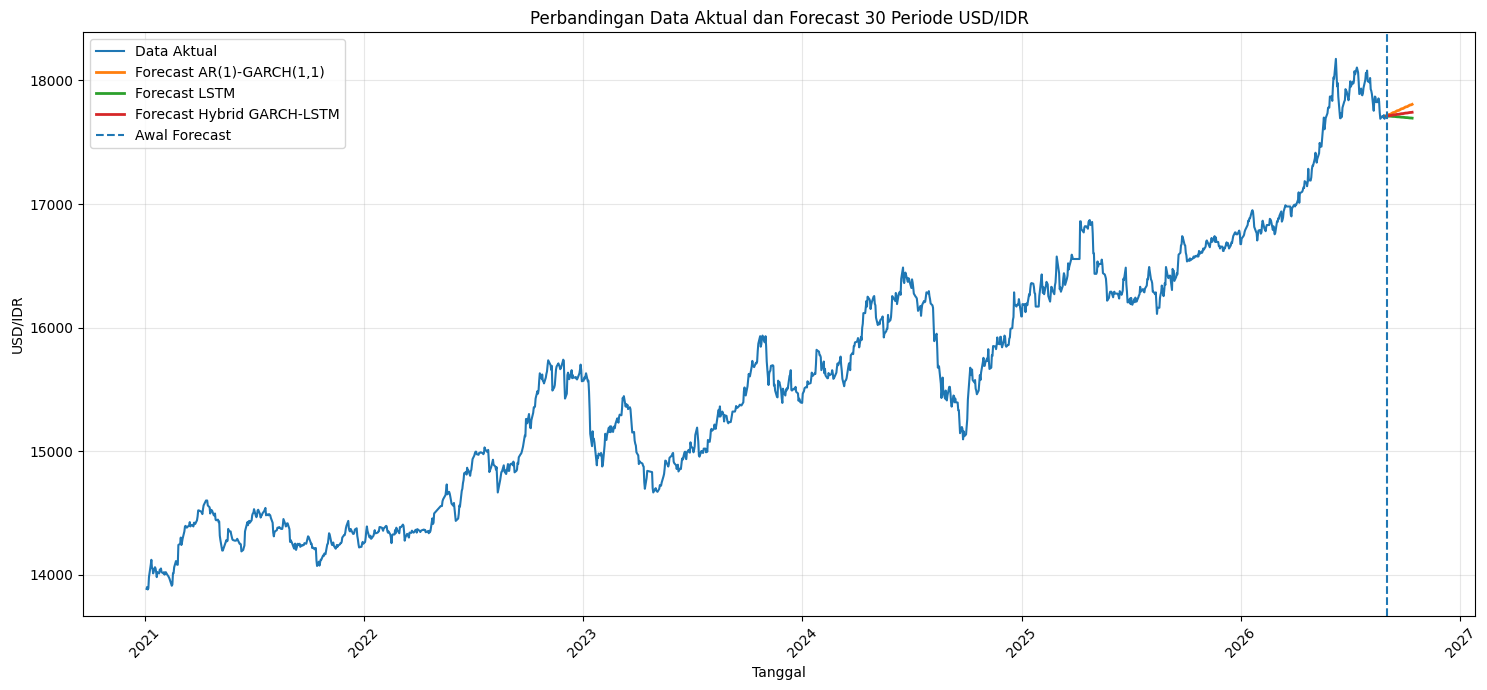

In [63]:
# ============================================================
# FORECASTING 30 PERIODE SETELAH SELURUH DATA HISTORIS
# AR(1)-GARCH(1,1), LSTM, DAN HYBRID GARCH-LSTM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model


# ============================================================
# 1. MENYIAPKAN DATA HISTORIS
# ============================================================

data_hist = data_return.copy()

data_hist["Tanggal"] = pd.to_datetime(data_hist["Tanggal"])
data_hist = data_hist.sort_values("Tanggal").reset_index(drop=True)

tanggal_hist = data_hist["Tanggal"]
harga_hist = data_hist["Kurs"].astype(float).to_numpy()
return_hist = data_hist["Log_Return"].astype(float).to_numpy()

return_hist_pct = return_hist * 100.0

HORIZON = 30

tanggal_terakhir = tanggal_hist.iloc[-1]
harga_terakhir = float(harga_hist[-1])

tanggal_future = pd.bdate_range(
    start=tanggal_terakhir + pd.Timedelta(days=1),
    periods=HORIZON
)

print("Tanggal historis terakhir:", tanggal_terakhir.date())
print("Tanggal awal forecasting:", tanggal_future[0].date())
print("Jumlah periode forecasting:", HORIZON)


# ============================================================
# 2. MEMBENTUK DATA TRAINING DAN TESTING
# ============================================================

# Menggunakan pembagian train-test yang sudah tersedia.
# Pastikan train dan test merupakan pembagian data_return
# yang sama dengan yang digunakan saat melatih model.

if "train" not in globals() or "test" not in globals():
    raise NameError(
        "Variabel train dan test belum tersedia. "
        "Bentuk pembagian data terlebih dahulu."
    )

if len(train) + len(test) != len(data_hist):
    raise ValueError(
        "Jumlah observasi train + test tidak sama dengan "
        "jumlah data historis. Periksa kembali pembagian data."
    )


# ============================================================
# 3. ROLLING ONE-STEP-AHEAD PADA DATA TESTING
# SIMPAN SEMUA HASIL DALAM DATAFRAME
# ============================================================

hasil_rolling = []

history_testing_pct = (
    train["Log_Return"].astype(float).to_numpy() * 100.0
).tolist()

for i in range(len(test)):

    model_roll = arch_model(
        np.asarray(history_testing_pct, dtype=float),
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    fit_roll = model_roll.fit(
        disp="off",
        show_warning=False
    )

    hasil_forecast_garch = fit_roll.forecast(
        horizon=1,
        reindex=False
    )

    prediksi_return_pct = float(
        hasil_forecast_garch.mean.iloc[-1, 0]
    )

    prediksi_return = prediksi_return_pct / 100.0

    aktual_return = float(
        test["Log_Return"].iloc[i]
    )

    residual_return = aktual_return - prediksi_return

    hasil_rolling.append({
        "Tanggal": test["Tanggal"].iloc[i],
        "Aktual_Log_Return": aktual_return,
        "Prediksi_Log_Return_GARCH": prediksi_return,
        "Residual_GARCH": residual_return
    })

    # Aktual dimasukkan setelah prediksi selesai
    history_testing_pct.append(
        aktual_return * 100.0
    )


# Simpan rolling forecasting ke DataFrame
hasil_forecast_historis = pd.DataFrame(hasil_rolling)

print("\nHASIL ROLLING ONE-STEP-AHEAD")
display(hasil_forecast_historis.head())


# ============================================================
# 4. MENYIAPKAN RESIDUAL TRAINING DAN TESTING UNTUK HYBRID
# ============================================================

# Residual training yang sudah digunakan saat melatih LSTM residual
residual_training_pct = np.asarray(
    residual_train_pct,
    dtype=float
).reshape(-1)

# Residual testing dikonversi ke skala persen
residual_testing_pct = (
    hasil_forecast_historis["Residual_GARCH"].to_numpy(dtype=float)
    * 100.0
)

# Gabungkan residual training dan testing
history_resid_pct = np.concatenate([
    residual_training_pct,
    residual_testing_pct
]).astype(float).tolist()

print("\nJumlah residual training:", len(residual_training_pct))
print("Jumlah residual testing:", len(residual_testing_pct))
print("Jumlah residual gabungan:", len(history_resid_pct))


# ============================================================
# 5. MENYIAPKAN RIWAYAT RETURN UNTUK SETIAP MODEL
# ============================================================

history_garch_pct = list(return_hist_pct)
history_lstm_pct = list(return_hist_pct)
history_hybrid_pct = list(return_hist_pct)


# ============================================================
# 6. FORECASTING REKURSIF 30 PERIODE
# ============================================================

pred_garch_pct_list = []
pred_lstm_pct_list = []
pred_residual_pct_list = []
pred_hybrid_pct_list = []

for i in range(HORIZON):

    # --------------------------------------------------------
    # A. AR(1)-GARCH(1,1)
    # --------------------------------------------------------

    model_garch = arch_model(
        np.asarray(history_garch_pct, dtype=float),
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    fit_garch = model_garch.fit(
        disp="off",
        show_warning=False
    )

    forecast_garch = fit_garch.forecast(
        horizon=1,
        method="analytic",
        reindex=False
    )

    pred_garch_pct = float(
        forecast_garch.mean.iloc[-1, 0]
    )

    pred_garch_pct_list.append(pred_garch_pct)


    # --------------------------------------------------------
    # B. LSTM
    # --------------------------------------------------------

    x_lstm = np.asarray(
        history_lstm_pct[-LOOKBACK:],
        dtype=float
    ).reshape(-1, 1)

    x_lstm_scaled = scaler_return.transform(x_lstm)

    x_lstm_scaled = x_lstm_scaled.reshape(
        1, LOOKBACK, 1
    )

    pred_lstm_scaled = float(
        model_lstm.predict(
            x_lstm_scaled,
            verbose=0
        )[0, 0]
    )

    pred_lstm_pct = float(
        scaler_return.inverse_transform(
            np.array([[pred_lstm_scaled]])
        )[0, 0]
    )

    pred_lstm_pct_list.append(pred_lstm_pct)


    # --------------------------------------------------------
    # C. LSTM RESIDUAL
    # --------------------------------------------------------

    x_resid = np.asarray(
        history_resid_pct[-LOOKBACK_RESID:],
        dtype=float
    ).reshape(-1, 1)

    x_resid_scaled = scaler_resid.transform(x_resid)

    x_resid_scaled = x_resid_scaled.reshape(
        1, LOOKBACK_RESID, 1
    )

    pred_resid_scaled = float(
        model_resid_lstm.predict(
            x_resid_scaled,
            verbose=0
        )[0, 0]
    )

    pred_resid_pct = float(
        scaler_resid.inverse_transform(
            np.array([[pred_resid_scaled]])
        )[0, 0]
    )

    pred_residual_pct_list.append(pred_resid_pct)


    # --------------------------------------------------------
    # D. KOMPONEN GARCH PADA HYBRID
    # --------------------------------------------------------

    model_garch_hybrid = arch_model(
        np.asarray(history_hybrid_pct, dtype=float),
        mean="AR",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    fit_garch_hybrid = model_garch_hybrid.fit(
        disp="off",
        show_warning=False
    )

    forecast_garch_hybrid = fit_garch_hybrid.forecast(
        horizon=1,
        method="analytic",
        reindex=False
    )

    pred_garch_hybrid_pct = float(
        forecast_garch_hybrid.mean.iloc[-1, 0]
    )


    # --------------------------------------------------------
    # E. HYBRID GARCH-LSTM
    # --------------------------------------------------------

    pred_hybrid_pct = (
        pred_garch_hybrid_pct + pred_resid_pct
    )

    pred_hybrid_pct_list.append(pred_hybrid_pct)


    # --------------------------------------------------------
    # F. PERBARUI RIWAYAT DENGAN HASIL PREDIKSI
    # --------------------------------------------------------

    history_garch_pct.append(pred_garch_pct)
    history_lstm_pct.append(pred_lstm_pct)
    history_hybrid_pct.append(pred_hybrid_pct)
    history_resid_pct.append(pred_resid_pct)

    print(
        f"Periode {i+1:02d}/{HORIZON} | "
        f"GARCH={pred_garch_pct:.6f} | "
        f"LSTM={pred_lstm_pct:.6f} | "
        f"Hybrid={pred_hybrid_pct:.6f}"
    )


# ============================================================
# 7. KONVERSI LOG RETURN KE SKALA ASLI
# ============================================================

pred_garch = np.asarray(pred_garch_pct_list) / 100.0
pred_lstm = np.asarray(pred_lstm_pct_list) / 100.0
pred_hybrid = np.asarray(pred_hybrid_pct_list) / 100.0


# ============================================================
# 8. REKONSTRUKSI KURS
# ============================================================

harga_garch = []
harga_lstm = []
harga_hybrid = []

p_garch = harga_terakhir
p_lstm = harga_terakhir
p_hybrid = harga_terakhir

for i in range(HORIZON):

    p_garch = p_garch * np.exp(pred_garch[i])
    p_lstm = p_lstm * np.exp(pred_lstm[i])
    p_hybrid = p_hybrid * np.exp(pred_hybrid[i])

    harga_garch.append(p_garch)
    harga_lstm.append(p_lstm)
    harga_hybrid.append(p_hybrid)


# ============================================================
# 9. SIMPAN HASIL FORECASTING 30 PERIODE KE DATAFRAME
# ============================================================

hasil_forecast_30 = pd.DataFrame({
    "Tanggal": tanggal_future,
    "Prediksi_Log_Return_GARCH": pred_garch,
    "Prediksi_Log_Return_LSTM": pred_lstm,
    "Prediksi_Log_Return_Hybrid": pred_hybrid,
    "Prediksi_Harga_GARCH": harga_garch,
    "Prediksi_Harga_LSTM": harga_lstm,
    "Prediksi_Harga_Hybrid": harga_hybrid
})

print("\nHASIL FORECASTING 30 PERIODE")
display(hasil_forecast_30)


# ============================================================
# 10. GRAFIK DATA AKTUAL DAN FORECASTING
# ============================================================

tanggal_plot = pd.DatetimeIndex(
    [tanggal_terakhir]
).append(
    pd.DatetimeIndex(tanggal_future)
)

garis_garch = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_garch)
])

garis_lstm = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_lstm)
])

garis_hybrid = np.concatenate([
    [harga_terakhir],
    np.asarray(harga_hybrid)
])

plt.figure(figsize=(15, 7))

plt.plot(
    tanggal_hist,
    harga_hist,
    label="Data Aktual",
    linewidth=1.5
)

plt.plot(
    tanggal_plot,
    garis_garch,
    label="Forecast AR(1)-GARCH(1,1)",
    linewidth=2
)

plt.plot(
    tanggal_plot,
    garis_lstm,
    label="Forecast LSTM",
    linewidth=2
)

plt.plot(
    tanggal_plot,
    garis_hybrid,
    label="Forecast Hybrid GARCH-LSTM",
    linewidth=2
)

plt.axvline(
    tanggal_terakhir,
    linestyle="--",
    label="Awal Forecast"
)

plt.title(
    "Perbandingan Data Aktual dan Forecast 30 Periode USD/IDR"
)

plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [64]:
# ============================================================
# PEMERIKSAAN HASIL FORECASTING
# ============================================================

kolom_return = [
    "Prediksi_Log_Return_GARCH",
    "Prediksi_Log_Return_LSTM",
    "Prediksi_Log_Return_Hybrid"
]

print("STATISTIK LOG RETURN HISTORIS")
print(
    data_return["Log_Return"]
    .astype(float)
    .describe()
)

print("\nSTATISTIK LOG RETURN FORECAST 30 PERIODE")

for kolom in kolom_return:
    print(f"\n{kolom}")
    print(hasil_forecast_30[kolom].describe())

print("\nPERBANDINGAN RETURN HISTORIS DAN FORECAST")

perbandingan = pd.DataFrame({
    "Ukuran": ["Mean", "Std", "Minimum", "Maksimum"],
    "Historis": [
        data_return["Log_Return"].mean(),
        data_return["Log_Return"].std(),
        data_return["Log_Return"].min(),
        data_return["Log_Return"].max()
    ],
    "GARCH": [
        hasil_forecast_30["Prediksi_Log_Return_GARCH"].mean(),
        hasil_forecast_30["Prediksi_Log_Return_GARCH"].std(),
        hasil_forecast_30["Prediksi_Log_Return_GARCH"].min(),
        hasil_forecast_30["Prediksi_Log_Return_GARCH"].max()
    ],
    "LSTM": [
        hasil_forecast_30["Prediksi_Log_Return_LSTM"].mean(),
        hasil_forecast_30["Prediksi_Log_Return_LSTM"].std(),
        hasil_forecast_30["Prediksi_Log_Return_LSTM"].min(),
        hasil_forecast_30["Prediksi_Log_Return_LSTM"].max()
    ],
    "Hybrid": [
        hasil_forecast_30["Prediksi_Log_Return_Hybrid"].mean(),
        hasil_forecast_30["Prediksi_Log_Return_Hybrid"].std(),
        hasil_forecast_30["Prediksi_Log_Return_Hybrid"].min(),
        hasil_forecast_30["Prediksi_Log_Return_Hybrid"].max()
    ]
})

display(perbandingan.round(8))


STATISTIK LOG RETURN HISTORIS
count    1441.000000
mean        0.000153
std         0.003182
min        -0.023397
25%        -0.001237
50%         0.000000
75%         0.001891
max         0.018256
Name: Log_Return, dtype: float64

STATISTIK LOG RETURN FORECAST 30 PERIODE

Prediksi_Log_Return_GARCH
count    30.000000
mean      0.000172
std       0.000002
min       0.000165
25%       0.000171
50%       0.000172
75%       0.000174
max       0.000175
Name: Prediksi_Log_Return_GARCH, dtype: float64

Prediksi_Log_Return_LSTM
count    30.000000
mean     -0.000037
std       0.000017
min      -0.000109
25%      -0.000036
50%      -0.000035
75%      -0.000034
max      -0.000014
Name: Prediksi_Log_Return_LSTM, dtype: float64

Prediksi_Log_Return_Hybrid
count    30.000000
mean      0.000052
std       0.000022
min      -0.000047
25%       0.000054
50%       0.000057
75%       0.000059
max       0.000070
Name: Prediksi_Log_Return_Hybrid, dtype: float64

PERBANDINGAN RETURN HISTORIS DAN FORECAST


,Ukuran,Historis,GARCH,LSTM,Hybrid
0,Mean,0.000153,0.000172,-0.000037,0.000052
1,Std,0.003182,0.000002,0.000017,0.000022
2,Minimum,-0.023397,0.000165,-0.000109,-0.000047
3,Maksimum,0.018256,0.000175,-0.000014,0.000070


In [66]:
# ============================================================
# 1. SKALA DATA RETURN TRAINING DAN SELURUH HISTORIS
# ============================================================

print("STATISTIK RETURN TRAINING")
print(
    train["Log_Return"]
    .astype(float)
    .describe()
)

print("\nSTATISTIK RETURN SELURUH HISTORIS")
print(
    data_return["Log_Return"]
    .astype(float)
    .describe()
)


# ============================================================
# 2. SKALA DATA YANG DIGUNAKAN OLEH SCALER RETURN
# ============================================================

print("\nSCALER RETURN")

print("Data minimum scaler:", scaler_return.data_min_)
print("Data maksimum scaler:", scaler_return.data_max_)
print("Rentang fitur scaler:", scaler_return.feature_range)


# ============================================================
# 3. BANDINGKAN RETURN TRAINING DENGAN PREDIKSI LSTM
# ============================================================

print("\nPREDIKSI LSTM 30 PERIODE")
print(
    hasil_forecast_30["Prediksi_Log_Return_LSTM"]
    .describe()
)

print("\nRETURN HISTORIS TERAKHIR")
print(
    data_return["Log_Return"]
    .tail(10)
    .to_list()
)


# ============================================================
# 4. PERIKSA SKALA RESIDUAL TRAINING DAN TESTING
# ============================================================

residual_training_check = np.asarray(
    residual_train_pct,
    dtype=float
).reshape(-1)

residual_testing_check = (
    hasil_forecast_historis["Residual_GARCH"]
    .to_numpy(dtype=float) * 100
)

print("\nRESIDUAL TRAINING (SKALA PERSEN)")
print(pd.Series(residual_training_check).describe())

print("\nRESIDUAL TESTING (SKALA PERSEN)")
print(pd.Series(residual_testing_check).describe())


# ============================================================
# 5. PERIKSA APAKAH INPUT LSTM TERAKHIR KELUAR DARI RENTANG
#    DATA TRAINING YANG DIGUNAKAN SCALER
# ============================================================

return_terakhir_pct = (
    data_return["Log_Return"]
    .tail(LOOKBACK)
    .to_numpy(dtype=float)
    .reshape(-1, 1) * 100
)

return_terakhir_scaled = scaler_return.transform(
    return_terakhir_pct
)

print("\nINPUT LSTM TERAKHIR DALAM SKALA PERSEN")
print(return_terakhir_pct.reshape(-1))

print("\nINPUT LSTM TERAKHIR SETELAH SCALING")
print(return_terakhir_scaled.reshape(-1))

print(
    "\nJumlah input LSTM di luar rentang [0, 1]:",
    np.sum(
        (return_terakhir_scaled < 0)
        | (return_terakhir_scaled > 1)
    )
)


STATISTIK RETURN TRAINING
count    1152.000000
mean        0.000118
std         0.003268
min        -0.023397
25%        -0.001303
50%         0.000000
75%         0.001906
max         0.018256
Name: Log_Return, dtype: float64

STATISTIK RETURN SELURUH HISTORIS
count    1441.000000
mean        0.000153
std         0.003182
min        -0.023397
25%        -0.001237
50%         0.000000
75%         0.001891
max         0.018256
Name: Log_Return, dtype: float64

SCALER RETURN
Data minimum scaler: [-2.33971675]
Data maksimum scaler: [1.82557816]
Rentang fitur scaler: (0, 1)

PREDIKSI LSTM 30 PERIODE
count    30.000000
mean     -0.000037
std       0.000017
min      -0.000109
25%      -0.000036
50%      -0.000035
75%      -0.000034
max      -0.000014
Name: Prediksi_Log_Return_LSTM, dtype: float64

RETURN HISTORIS TERAKHIR
[-0.0014011491713628033, -0.004919540458047322, -0.002963383245306872, 0.0011299436230469695, 0.0, -0.0005648122149590762, 0.0011293055971517418, -0.0016944370052396351, 0.